# VS code cũng đẹp mà
Tui yêu cái đẹp, thấy cái gì đẹp là tui lưu lại hết à
Tui muốn sản phẩm mk làm ra có sự chỉnh chu, áp dụng được vào thực tiễn, thực sự có ích cho đời

In [1]:
# import libraries 

import numpy as np
import pandas as pd
import unicodedata
import re


#Vẽ biểu đồ
import matplotlib.pyplot as plt 

# Vẽ biểu đồ nhiệt
import seaborn as sns

from collections import Counter

In [5]:
# review file data
filename = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\Crawl_job\Data_raw\data_itviec.csv"

df=pd.read_csv(filename)
df

,index,job_url,search_keyword,job_title,company_name,location,salary,is_fresher,job_type,date_post,job_skills,job_expertise,job_domain,company_industry,company_type,company_country,job_description,requirements,benefits,source_site
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,No,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,Materials and Mining,IT Outsourcing,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,"Banking, Financial Services",Banking,IT Product,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,No,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,Software Products and Web Services,IT Product,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",No,At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,"E-commerce, Software Products and Web Services",E-commerce,IT Product,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,No,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,Education and Training,IT Product,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,Yes,At office,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",Mobile Application Developer,Software Products and Web Services,Software Products and Web Services,IT Product,Singapore,We are looking for a Junior Android Developer ...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,Yes,At office,2026-06-12,"iOS, API, Database, OOP, Swift, English",Mobile Application Developer,Software Products and Web Services,Software Products and Web Services,IT Product,Singapore,1. Education ● Bachelor’s degree in Computer S...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary wit

# 1. ___ THÊM CỘT BỊ THIẾU THÔNG TIN _______________

## 1.1. thêm cột `Năm kinh nghiệm`

In [ ]:
# 1. Đưa patterns ra ngoài và dùng re.compile để tối ưu tốc độ

'''
Tiếng Anh:
    X+ years of experience
    at least X years of experience
    minimum X years
    X+ years in ...
    X+ years experiences
    X - Y years of experience

Tiếng Việt:
    tối thiểu X năm kinh nghiệm
    ít nhất X năm kinh nghiệm
    có từ X năm kinh nghiệm
    tối thiểu từ X-Y năm kinh nghiệm

'''

# Bọc thêm một dấu ngoặc đơn lớn ở ngoài để lấy NGUYÊN CỤM TỪ
EXP_PATTERNS = [
    # =========================================================================
    # 1. DẠNG PHẠM VI (RANGE) - LUÔN ƯU TIÊN CHẠY TRƯỚC
    # =========================================================================
    # "2-5 years of experience", "2–5+ years working experience", "1 - 3 year ... experience"
    (r'((\d+)\s*[-–]\s*(\d+)\+?\s*years?.*?experience)', 'range'),
    
    # "2 - 3 năm kinh nghiệm"
    (r'((\d+)\s*[-–]\s*(\d+)\s*năm kinh nghiệm)', 'range'),


    # =========================================================================
    # 2. DẠNG TIẾNG ANH (SINGLE)
    # =========================================================================
    
    # "at least 2 years of experience", "3+ years working experience", "minimum 2 year full-stack experience"
    (r'((?:at least\s*|minimum\s*)?(\d+)\+?\s*years?.*?experience)', 'single'), 
    
    (r'(experience\s*minimum\s*(\d+)\s*years?)', 'single'), # "experience minimum X" / "experience minimum X years"
    (r'((\d+)\+\s*years? in)', 'single'),                   # "X+ years in"
    (r'(minimum\s*(\d+)\s*years?)', 'single'),              # "minimum X years"
    (r'((\d+)\s*years?\s*as\s*a)', 'single'),               # "X years as a ..." 


    # =========================================================================
    # 3. DẠNG TIẾNG VIỆT (SINGLE)
    # =========================================================================
    # 
    (r'(có kinh nghiệm tối thiểu\s*(\d+)\s*năm)', 'single'),    # "có kinh nghiệm tối thiểu X năm"
    (r'(tối thiểu từ\s*(\d+)\s*năm)', 'single'),                # tối thiểu từ 57 năm
    (r'(tối thiểu\s*(\d+)\s*năm kinh nghiệm)', 'single'),       # "tối thiểu X năm kinh nghiệm"
    (r'(ít nhất\s*(\d+)\s*năm kinh nghiệm)', 'single'),         # "ít nhất X năm kinh nghiệm"
    (r'(có từ\s*(\d+)\s*năm kinh nghiệm)', 'single'),           # "có từ X năm kinh nghiệm"
    (r'((\d+)\+\s*năm kinh nghiệm)', 'single'),                 # "X+ năm kinh nghiệm" (có dấu +)
    (r'(kinh nghiệm từ\s*(\d+)\s*năm)', 'single'),              # "kinh nghiệm từ X năm"
    (r'((\d+)\s*năm kinh nghiệm)', 'single'),                   # "X năm kinh nghiệm"
]


# Compile regex trước (tăng tốc độ chạy lên nhiều lần)
COMPILED_PATTERNS = [(re.compile(pat), typ) for pat, typ in EXP_PATTERNS]

In [ ]:
# Hàm thêm cột kinh nghiệm

def extract_experience_with_context(text):
    if not isinstance(text, str):
        return None, None
    text = text.lower()
    
    for regex_obj, typ in COMPILED_PATTERNS:
        m = regex_obj.search(text)
        if m:
            full_phrase = m.group(1) # Lấy nguyên cụm từ
            val = int(m.group(2))    # Số X đầu tiên
            
            # Xử lý case lạ lỗi crawl
            if val >= 20 and val < 30 and "2" in full_phrase: 
                val = 2
                
            # Xử lý case lạ lỗi crawl
            if val >= 30 and val < 40 and "3" in full_phrase: 
                val = 3
                
            # Xử lý case lạ lỗi crawl
            if val >= 40 and val < 50 and "4" in full_phrase: 
                val = 4   

            # Xử lý case lạ lỗi crawl
            if ((val >= 50 and val < 60) or (val >= 500 and val < 600)) and "5" in full_phrase: 
                val = 5
                
            # Xử lý case lạ lỗi crawl
            if ((val >= 60 and val < 70) or (val >= 600 and val < 700)) and "6" in full_phrase: 
                val = 6                

            # Xử lý case lạ lỗi crawl
            if "203" in full_phrase: 
                val = 2
                                         
            # Xử lý case lạ lỗi crawl
            if val >= 1000 and "10" in full_phrase: 
                val = 10
                
            #if val > 20: # Loại bỏ các giá trị vô lý
              #  continue
                
            return val, full_phrase
            
    return None, None



In [8]:
# --- Áp dụng tạo cột mới là kết hợp cột yêu cầu và cột mô tả ---
df['text_combined'] = df['job_description'].fillna('') + ' ' + df['requirements'].fillna('')

In [19]:
# CÁCH TỐT NHẤT: Trả về pd.Series để tự động phân rã vào 2 cột
df[['experience_min_year', 'experience_phrase']] = df['text_combined'].apply(
    lambda x: pd.Series(extract_experience_with_context(x))
)

In [20]:
df

,index,job_url,search_keyword,job_title,company_name,location,salary,is_fresher,job_type,date_post,...,company_industry,company_type,company_country,job_description,requirements,benefits,source_site,text_combined,experience_min_year,experience_phrase
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,No,At office,2026-04-05,...,Materials and Mining,IT Outsourcing,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com,"Main Mission Within the Data & AI Hub, you wil...",3.0,"35 years postsecondary) in computer science, s..."
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-04-04,...,Banking,IT Product,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,1.0,tối thiểu 1 năm kinh nghiệm
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,No,Hybrid,2026-04-02,...,Software Products and Web Services,IT Product,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com,"At Goelett by S4BT, we are a dynamic team pass...",NaN,None
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",No,At office,2026-04-02,...,E-commerce,IT Product,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com,ABOUT THE ROLE Crossian is a highgrowth techno...,2.0,2–5+ years of work experience
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,No,At office,2026-04-01,...,Education and Training,IT Product,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com,"About TeenCare AI At TeenCare AI , we work at ...",2.0,2+ years in
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,Yes,At office,2026-06-12,...,Software Products and Web Services,IT Product,Singapore,We are looking for a Junior Android Developer ...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com,We are looking for a Junior Android Developer ...,NaN,None
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,Yes,At office,2026-06-12,...,Software Products and Web Services,IT Product,Singapore,1. Education ● Bachelor’s degree in Computer S...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com,1. Education ● Bachelor’s degree in Computer S...,NaN,None
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Adminis

In [ ]:
df[df['experience_min_year'] > 10].sort_values(by='experience_min_year', ascending=True)

,index,job_url,search_keyword,job_title,company_name,location,salary,is_fresher,job_type,date_post,...,company_industry,company_type,company_country,job_description,requirements,benefits,source_site,text_combined,experience_min_year,experience_phrase
596,597,https://itviec.com/it-jobs/enterprise-architec...,Cloud Data,Enterprise Architect (TOGAF 9.x),GALAXY HOLDINGS,"Galaxy Innovation Hub, đường D1, Khu Công nghệ...",You'll love it,No,At office,2026-04-25,...,Software Products and Web Services,IT Product,Vietnam,Định hình và quản trị kiến trúc công nghệ tổng...,Tối thiểu 12 năm kinh nghiệm trong lĩnh vực CN...,"Mức lương cạnh tranh top thị trường, thưởng hi...",itviec.com,Định hình và quản trị kiến trúc công nghệ tổng...,12.0,tối thiểu 12 năm kinh nghiệm
797,798,https://itviec.com/it-jobs/enterprise-architec...,Cloud Data,"Enterprise Architect (TOGAF 9.x, AWS/Azure/GCP)",GALAXY HOLDINGS,"Galaxy Innovation Hub, đường D1, Khu Công nghệ...",NaN,No,At office,2026-05-10,...,Software Products and Web Services,IT Product,Vietnam,Định hình và quản trị kiến trúc công nghệ tổng...,Tối thiểu 12 năm kinh nghiệm trong lĩnh vực CN...,"Mức lương cạnh tranh top thị trường, thưởng hi...",itviec.com,Định hình và quản trị kiến trúc công nghệ tổng...,12.0,tối thiểu 12 năm kinh nghiệm
447,448,https://itviec.com/it-jobs/senior-manager-it-i...,Cloud Data,Senior Manager IT Infrastructure (Networking/L...,Gene Solutions,"366 Nguyễn Trãi, Ho Chi Minh",You'll love it,No,At office,2026-04-16,...,Healthcare,IT Product,Vietnam,Gene Solutions is a leading company in Vietnam...,Bachelor’s degree or higher in Computer Scienc...,13th month salary. Holidays and full annual le...,itviec.com,Gene Solutions is a leading company in Vietnam...,13.0,minimum 13 years in it infrastructure technolo...
391,392,https://itviec.com/it-jobs/senior-qa-automatio...,Data Quality Analyst,Senior QA Automation Engineer,OL Vietnam,"Tòa nhà Saigon Trade Center (37 Tôn Đức Thắng,...",NaN,No,At office,2026-03-21,...,Software Products and Web Services,IT Product,United States,"At OL Vietnam , we have been working with our ...",Responsibilities: Strategize the delivery of t...,You would love to work and find those values w...,itviec.com,"At OL Vietnam , we have been working with our ...",15.0,"15+ years of independent r&d, cortex is the mo..."


In [ ]:
 # Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['text_combined', 'experience_phrase'])

In [ ]:
### Saved
df.to_csv("data_ITviec_1.csv", index=False, encoding="utf-8-sig")

## 1.2. Thêm cột edu

In [3]:
# review file data
filename = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_1.csv"
df=pd.read_csv(filename)

df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,salary,is_fresher,job_type,date_post,...,job_expertise,job_domain,company_industry,company_type,company_country,job_description,requirements,benefits,source_site,experience_min_year
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,No,At office,2026-04-05,...,Data Analyst,Materials and Mining,Materials and Mining,IT Outsourcing,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com,3.0
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-04-04,...,Data Analyst,"Banking, Financial Services",Banking,IT Product,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com,1.0
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,No,Hybrid,2026-04-02,...,Data Analyst,Software Products and Web Services,Software Products and Web Services,IT Product,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com,NaN
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",No,At office,2026-04-02,...,Data Analyst,"E-commerce, Software Products and Web Services",E-commerce,IT Product,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com,2.0
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,No,At office,2026-04-01,...,Data Analyst,Education and Training,Education and Training,IT Product,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com,2.0
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,"12th Floor, 68 Phan Dang Luu, Duc Nhuan Ward, ...","1,500 - 3,900 USD",No,At office,2026-03-31,...,Data Analyst,"E-commerce, IT Services and IT Consulting, Sof...",Software Products and Web Services,IT Product,Vietnam,Define requirements with stakeholders and coun...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,itviec.com,NaN
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,"The Capital Place, 29 Lieu Giai Street, Ngoc H...","1,000 - 3,500 USD",No,Hybrid,2026-03-30,...,Data Analyst,"Banking, Financial Services",Banking,IT Product,Australia,ABOUT THE JOB We are seeking motivated Fraud D...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,itviec.com,4.0
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-03-25,...,Data Analyst,"Banking, Financial Services",Banking,IT Product,Vietnam,HO26.76 Chuyên viên Phân tích và thiết kế Mô h...,1. Trình độ học vấn Tốt nghiệp Đại học (bằng k...,Trải nghiệm Thu nhập hấp dẫn vớ

In [5]:
# 1. KHAI BÁO CÁC PATTERN TÌM KIẾM HỌC VẤN
# Phân loại từ khóa theo cấp độ: Master hoặc Bachelor
EDU_PATTERNS = [
    # Cao đẳng
    (r"cao đẳng", "Cao đẳng"),
    (r"college(?:'s)?\s*(?:degree|of)?" , "Cao đẳng"),
    
    # Cấp độ Bachelor (Đại học)
    (r"bachelor(?:'s)?\s*(?:degree|of)?", "Đại học"),
    (r"university(?:'s)?\s*(?:degree)?" , "Đại học"),
    (r"fresh graduate", "Đại học"),
    (r"đại học",        "Đại học"),
    (r"cử nhân",        "Đại học"),
    
    # Cấp độ Master, Nghiên cứu sinh (Cao học)
    (r"master(?:'s)?\s*(?:degree|of)?", "Cao học"),
    (r'(?:mba|msc|ph\.?d|postgraduate|thạc sĩ|tiến sĩ|cao học)', 'Cao học'),
]
# Compile regex trước để tối ưu tốc độ
COMPILED_EDU_PATTERNS = [(re.compile(pat), level) for pat, level in EDU_PATTERNS]

In [ ]:
# 2. HÀM TRÍCH XUẤT HỌC VẤN
def extract_education(text):
    if not isinstance(text, str):
        return None
    
    text = text.lower()
    found_levels = set()
    
    # Quét văn bản với từng regex
    for regex_obj, level in COMPILED_EDU_PATTERNS:
        if regex_obj.search(text):
            found_levels.add(level)
            
    # CHUỖI XÉT DUYỆT TỪ THẤP ĐẾN CAO (Yêu cầu tối thiểu)
    # Rơi vào cái nào thấp nhất thì chốt luôn cái đó.
    if "Cao đẳng" in found_levels:
        return "Cao đẳng"
    elif "Đại học" in found_levels:
        return "Đại học"
    elif "Cao học" in found_levels:
        return "Cao học"
    
    return "Not Mentioned"

# 3. ÁP DỤNG ĐỂ TẠO CỘT MỚI
# Tạo cột "edu"
df['edu'] = df['text_combined'].apply(extract_education)

In [10]:
# In thử 10 dòng ra xem kết quả
df

,index,job_url,search_keyword,job_title,company_name,location,salary,is_fresher,job_type,date_post,...,company_industry,company_type,company_country,job_description,requirements,benefits,source_site,experience_min_year,text_combined,edu
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,No,At office,2026-04-05,...,Materials and Mining,IT Outsourcing,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-04-04,...,Banking,IT Product,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,No,Hybrid,2026-04-02,...,Software Products and Web Services,IT Product,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",No,At office,2026-04-02,...,E-commerce,IT Product,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,No,At office,2026-04-01,...,Education and Training,IT Product,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,Yes,At office,2026-06-12,...,Software Products and Web Services,IT Product,Singapore,We are looking for a Junior Android Developer ...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com,NaN,We are looking for a Junior Android Developer ...,Đại học
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,Yes,At office,2026-06-12,...,Software Products and Web Services,IT Product,Singapore,1. Education ● Bachelor’s degree in Computer S...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com,NaN,1. Education ● Bachelor’s degree in Computer S...,Đại học
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,"Tầng 8, Tòa nhà Hapr

In [11]:
# Giả sử bạn có dataframe tên là df và cột cần tính là 'edu'
tan_suat = df['edu'].value_counts()
print(tan_suat)

edu
Đại học          528
Not Mentioned    505
Cao học           90
Cao đẳng          25
Name: count, dtype: int64


In [ ]:
# Giả sử bạn có dataframe tên là df và cột cần tính là 'experience_min_year'
df['experience_min_year'].value_counts()

experience_min_year
3.0     235
5.0     223
2.0     172
4.0      70
1.0      69
7.0      46
6.0      24
10.0     20
8.0      18
0.0       4
12.0      2
15.0      1
13.0      1
9.0       1
Name: count, dtype: int64

In [12]:
### Saved
df.to_csv("data_ITviec_2.csv", index=False, encoding="utf-8-sig")

## 1.3. Thêm cột cấp độ nhân viên

In [5]:
# review file data
filename = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_2.csv"
df = pd.read_csv(filename)

df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,salary,is_fresher,job_type,date_post,...,company_industry,company_type,company_country,job_description,requirements,benefits,source_site,experience_min_year,text_combined,edu
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,No,At office,2026-04-05,...,Materials and Mining,IT Outsourcing,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-04-04,...,Banking,IT Product,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,No,Hybrid,2026-04-02,...,Software Products and Web Services,IT Product,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",No,At office,2026-04-02,...,E-commerce,IT Product,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,No,At office,2026-04-01,...,Education and Training,IT Product,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,"12th Floor, 68 Phan Dang Luu, Duc Nhuan Ward, ...","1,500 - 3,900 USD",No,At office,2026-03-31,...,Software Products and Web Services,IT Product,Vietnam,Define requirements with stakeholders and coun...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,itviec.com,NaN,Define requirements with stakeholders and coun...,Đại học
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,"The Capital Place, 29 Lieu Giai Street, Ngoc H...","1,000 - 3,500 USD",No,Hybrid,2026-03-30,...,Banking,IT Product,Australia,ABOUT THE JOB We are seeking motivated Fraud D...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,itviec.com,4.0,ABOUT THE JOB We are seeking motivated Fraud D...,Not Mentioned
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,No,At office,2026-03-25,...,Banking,IT Product,Vietnam,HO26.76 Chuyên viên Phân tích và thiết kế Mô h...,1. Trình độ học vấn Tốt nghiệp Đại học

In [32]:
# Làm sạch Tilte

def clean_vietnamese_text(text):
    """Hàm làm sạch và chuẩn hóa văn bản"""
    if pd.isna(text):
        return ""
    
    # 1. Chuyển về chữ thường
    text = str(text).lower()
    
    # 2. Loại bỏ dấu tiếng Việt (thực tập -> thuc tap)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8')
    
    # 3. Thay thế các ký tự đặc biệt (-, _) bằng khoảng trắng
    text = text.replace('-', ' ').replace('_', ' ')
    
    # 4. Xóa khoảng trắng thừa và khoảng trắng hai đầu
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [ ]:
def assign_job_level(title):
    t = clean_vietnamese_text(title)
    if not t:
        return "Undefined"
    
    # ƯU TIÊN 1: Intern (Hễ có intern/thực tập là auto Level 1)
    level_1_keywords = ['intern', 'thuc tap', 'hoc viec', 'young talent', 'trainee', 'tap su', 'sinh vien', 
                        'apprentice', 'ctv', 'cong tac vien']
    if any(k in t for k in level_1_keywords):
        return "Intern"
        
    # ƯU TIÊN 2: Fresher
    level_2_keywords = ['fresher', 'moi tot nghiep', 'moi ra truong', 'entry level', 'graduate', 'new grad']
    if any(k in t for k in level_2_keywords):
        return "Fresher"
        
    # ƯU TIÊN 3: Junior / Middle / Support
    # Đã gộp nhóm "trợ lý, assistant, thư ký, secretary, support" vào đây để ưu tiên bắt dính Level 3 trước
    level_3_keywords = ['tro ly', 'assistant', 'thu ky', 'secretary', 'support',
                        'junior', 'chuyen vien', 'specialist', 'mid level']
    if any(k in t for k in level_3_keywords):
        return "Junior/Middle"
        
    # ƯU TIÊN 4: Senior
    level_4_keywords = ['senior', 'sr.', 'cao cap', 'chuyen gia', 'expert', 'principal', 'snr']
    if any(k in t for k in level_4_keywords):
        return "Senior"
        
    # ƯU TIÊN 5: Manager / Director (Chốt chặn cuối cùng, rớt qua 4 ải trên mới được làm sếp)
    level_5_keywords = ['manager', 'lead', 'head', 'director', 'truong phong', 'truong nhom', 'quan ly', 'CEO', 'CTO', 'CFO', 'COO',
                        'supervisor', 'giam sat', 'truong nhom', 'pho phong', 'chief', 'vice president', 'giam doc']
    if any(k in t for k in level_5_keywords):
        return "Manager/Lead"
        
    # Những job title quá "lạ" không dính từ khóa nào:
    return "Undefined"

In [19]:
# ==========================================
# TEST THỬ VỚI VÀI DATA THỰC TẾ:
# ==========================================
test_titles = [
    "Chuyên viên cao cấp Phân tích Dữ liệu", 
    "Data Analyst (Entry-level)", 
    "Thuc tap sinh IT", 
    "Senior_Data_Engineer",
    "Trợ lý giám đốc",
    "Cộng tác viên viết bài"
]
for title in test_titles:
    print(f"Title gốc: '{title}' -> Level: {assign_job_level(title)}")

Title gốc: 'Chuyên viên cao cấp Phân tích Dữ liệu' -> Level: Junior/Middle
Title gốc: 'Data Analyst (Entry-level)' -> Level: Fresher
Title gốc: 'Thuc tap sinh IT' -> Level: Intern
Title gốc: 'Senior_Data_Engineer' -> Level: Senior
Title gốc: 'Trợ lý giám đốc' -> Level: Junior/Middle
Title gốc: 'Cộng tác viên viết bài' -> Level: Intern


In [24]:
# Tạo cột mới 'job_level' dựa trên cột 'job_title'
df['job_level_test'] = df['job_title'].apply(assign_job_level)

# In thử ra xem kết quả nhé:
df[['job_title', 'job_level_test']]

,job_title,job_level_test
0,Data Analyst/ Power BI Developer,Undefined
1,Business Customer Data Analyst - Data Division,Undefined
2,"Data Analyst (Power BI, MSSQL, Python)",Undefined
3,"Supply Chain Data Analyst (Total up-to 34,000 ...",Undefined
4,"Data Analyst (SQL, BI tools) for Edtech project",Undefined
...,...,...
1143,Junior Android Developer (Kotlin/Java),Junior/Middle
1144,"Junior iOS Mobile Developer (Swift, English)",Junior/Middle
1145,"Senior Backend Developer (Java Spring Boot, BPM)",Senior
1146,[Senior/ Lead] Fullstack Engineer,Senior


In [25]:
df['job_level_test'].value_counts()

job_level_test
Undefined        557
Senior           365
Manager/Lead     107
Junior/Middle     89
Intern            19
Fresher           11
Name: count, dtype: int64

In [ ]:
# ghép cột check `is_intern`

# 1. Đọc file data intern
filename_intern = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\Crawl_job\Data_raw\data_itviec_intern.csv"
df_intern = pd.read_csv(filename_intern)

# 2. Ghép ngang (axis=1) chỉ riêng cột 'is_intern' vào bảng chính
df = pd.concat([df, df_intern[['is_intern']]], axis=1)

In [26]:
# 3. Check
df[['job_title', 'is_intern', 'is_fresher', 'job_level_test']]

,job_title,is_intern,is_fresher,job_level_test
0,Data Analyst/ Power BI Developer,No,No,Undefined
1,Business Customer Data Analyst - Data Division,No,No,Undefined
2,"Data Analyst (Power BI, MSSQL, Python)",No,No,Undefined
3,"Supply Chain Data Analyst (Total up-to 34,000 ...",No,No,Undefined
4,"Data Analyst (SQL, BI tools) for Edtech project",No,No,Undefined
...,...,...,...,...
1143,Junior Android Developer (Kotlin/Java),No,Yes,Junior/Middle
1144,"Junior iOS Mobile Developer (Swift, English)",No,Yes,Junior/Middle
1145,"Senior Backend Developer (Java Spring Boot, BPM)",No,No,Senior
1146,[Senior/ Lead] Fullstack Engineer,No,No,Senior


In [33]:
# 1. Liệt kê các điều kiện (if, elif)
conditions = [
    df['is_intern']  == 'Yes',
    df['is_fresher'] == 'Yes'
]
# 2. Liệt kê kết quả tương ứng với điều kiện
choices = [
    'Intern', 
    'Fresher'
]
# 3. Tạo cột mới (với tham số default chính là "else")
df['job_level'] = np.select(conditions, choices, default=df['job_level_test'])

In [34]:
# 3. Check
df[['job_title', 'is_intern', 'is_fresher', 'job_level_test', 'job_level']]

,job_title,is_intern,is_fresher,job_level_test,job_level
0,Data Analyst/ Power BI Developer,No,No,Undefined,Undefined
1,Business Customer Data Analyst - Data Division,No,No,Undefined,Undefined
2,"Data Analyst (Power BI, MSSQL, Python)",No,No,Undefined,Undefined
3,"Supply Chain Data Analyst (Total up-to 34,000 ...",No,No,Undefined,Undefined
4,"Data Analyst (SQL, BI tools) for Edtech project",No,No,Undefined,Undefined
...,...,...,...,...,...
1143,Junior Android Developer (Kotlin/Java),No,Yes,Junior/Middle,Fresher
1144,"Junior iOS Mobile Developer (Swift, English)",No,Yes,Junior/Middle,Fresher
1145,"Senior Backend Developer (Java Spring Boot, BPM)",No,No,Senior,Senior
1146,[Senior/ Lead] Fullstack Engineer,No,No,Senior,Senior


In [35]:
df['job_level'].value_counts()

job_level
Undefined        530
Senior           365
Manager/Lead     106
Junior/Middle     75
Fresher           52
Intern            20
Name: count, dtype: int64

In [36]:
 # Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['is_intern', 'is_fresher', 'job_level_test'])
df

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_post,job_skills,...,company_type,company_country,job_description,requirements,benefits,source_site,experience_min_year,text_combined,edu,job_level
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,IT Outsourcing,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học,Undefined
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,IT Product,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,Undefined
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,IT Product,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,Undefined
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,IT Product,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,Undefined
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,IT Product,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,Undefined
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,At office,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",...,IT Product,Singapore,We are looking for a Junior Android Developer ...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com,NaN,We are looking for a Junior Android Developer ...,Đại học,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Very attractive!!!,At office,2026-06-12,"iOS, API, Database, OOP, Swift, English",...,IT Product,Singapore,1. Education ● Bachelor’s degree in Computer S...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,itviec.com,NaN,1. Education ● Bachelor’s de

In [37]:
### Saved
df.to_csv("data_ITviec_3.csv", index=False, encoding="utf-8-sig")

## 1.4. Thêm cột date_deadline

In [5]:
# review file data
filename_3 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_3.csv"
df = pd.read_csv(filename_3)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1148 entries, 0 to 1147
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1148 non-null   int64  
 1   job_url              1148 non-null   object 
 2   search_keyword       1148 non-null   object 
 3   job_title            1148 non-null   object 
 4   company_name         1148 non-null   object 
 5   location             1148 non-null   object 
 6   salary               751 non-null    object 
 7   job_type             1148 non-null   object 
 8   date_post            1128 non-null   object 
 9   job_skills           1148 non-null   object 
 10  job_expertise        1148 non-null   object 
 11  job_domain           1148 non-null   object 
 12  company_industry     1129 non-null   object 
 13  company_type         1148 non-null   object 
 14  company_country      1148 non-null   object 
 15  job_description      1148 non-null   o

In [12]:
# 1. Chuyển đổi cột 'date_post' sang kiểu datetime (nếu chưa có)
df['date_post'] = pd.to_datetime(df['date_post'])

# 2. Thêm cột 'date_deadline' cộng thêm 1 tháng từ 'date_post'
df['date_deadline'] = df['date_post'] + pd.DateOffset(months=1)

df[['date_post','date_deadline']]


,date_post,date_deadline
0,2026-04-05,2026-05-05
1,2026-04-04,2026-05-04
2,2026-04-02,2026-05-02
3,2026-04-02,2026-05-02
4,2026-04-01,2026-05-01
...,...,...
1143,2026-06-12,2026-07-12
1144,2026-06-12,2026-07-12
1145,2026-06-12,2026-07-12
1146,2026-06-12,2026-07-12


In [13]:
# Chuyển đổi trực tiếp 2 cột từ datetime sang chỉ lấy phần ngày (date)
df['date_post'] = df['date_post'].dt.date
df['date_deadline'] = df['date_deadline'].dt.date

# Kiểm tra lại kết quả
df[['date_post','date_deadline']]

,date_post,date_deadline
0,2026-04-05,2026-05-05
1,2026-04-04,2026-05-04
2,2026-04-02,2026-05-02
3,2026-04-02,2026-05-02
4,2026-04-01,2026-05-01
...,...,...
1143,2026-06-12,2026-07-12
1144,2026-06-12,2026-07-12
1145,2026-06-12,2026-07-12
1146,2026-06-12,2026-07-12


In [16]:
df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_post,job_skills,...,company_country,job_description,requirements,benefits,source_site,experience_min_year,text_combined,edu,job_level,date_deadline
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,itviec.com,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học,Undefined,2026-05-05
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,itviec.com,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,Undefined,2026-05-04
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",itviec.com,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,Undefined,2026-05-02
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",itviec.com,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,Undefined,2026-05-02
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",itviec.com,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,Undefined,2026-05-01
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,"12th Floor, 68 Phan Dang Luu, Duc Nhuan Ward, ...","1,500 - 3,900 USD",At office,2026-03-31,"Python, SQL",...,Vietnam,Define requirements with stakeholders and coun...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,itviec.com,NaN,Define requirements with stakeholders and coun...,Đại học,Senior,2026-04-30
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,"The Capital Place, 29 Lieu Giai Street, Ngoc H...","1,000 - 3,500 USD",Hybrid,2026-03-30,"Python, SQL",...,Australia,ABOUT THE JOB We are seeking motivated Fraud D...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,itviec.com,4.0,ABOUT THE JOB We are seeking motivated Fraud D...,Not Mentioned,Senior,2026-04-30
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên H

## 1.5. Them cot Position

In [33]:
def assign_job_position(title):
    # Hàm clean_vietnamese_text sẽ biến chữ về dạng thường, không dấu (ví dụ: "Trưởng Phòng" -> "truong phong")
    t = clean_vietnamese_text(title)
    if not t:
        return "Không đề cập" 
    
    # ƯU TIÊN 1: Intern (Hễ có intern/thực tập là auto Level 1)
    level_1_keywords = ['intern', 'thuc tap', 'hoc viec', 'young talent', 'trainee', 'tap su', 'sinh vien', 
                        'apprentice', 'ctv', 'cong tac vien']
    if any(k in t for k in level_1_keywords):
        return "Intern"
        
    # ƯU TIÊN 2: Fresher
    level_2_keywords = ['fresher', 'moi tot nghiep', 'moi ra truong', 'entry level', 'graduate', 'new grad']
    if any(k in t for k in level_2_keywords):
        return "Fresher"
        
    
    # ƯU TIÊN 3: Nhân viên / Chuyên viên (Chốt chặn cuối cùng cho các từ còn lại)
    level_3_keywords = ['tro ly', 'thu ky', 'assistant', 'secretary', 'support',
                        'junior', 'chuyen vien', 'specialist', 'mid level', 'nhan vien']
    if any(k in t for k in level_3_keywords):
        return "Nhân viên"
     
    
    # ƯU TIÊN 4: Trưởng nhóm / Giám sát (Đẩy sếp nhỏ lên trước Nhân viên để tránh bị ăn non)
    # Ví dụ: Câu "chuyen vien truong nhom" nếu quét Nhân viên trước sẽ bị bắt nhầm thành Nhân viên
    level_4_keywords = ['senior', 'sr.', 'cao cap', 'chuyen gia', 'expert', 'principal', 'snr', 
                        'truong nhom', 'supervisor', 'giam sat', 'leader', 'team lead', 'team lead']
    if any(k in t for k in level_4_keywords):
        return "Trưởng nhóm" 
        
    
    # ƯU TIÊN 5: Trưởng phòng
    level_5_keywords = ['head', 'truong phong', 'pho phong', 'truong bo phan', 
                        'truong don vi', 'truong chi nhanh', 'truong van phong']
    if any(k in t for k in level_5_keywords):
        return "Trưởng phòng"
        
    # ƯU TIÊN 6: Lãnh đạo / Quản lý
    level_6_keywords = ['manager', 'director', 'quan ly', 'ceo', 'cto', 'cfo', 'coo',
                        'chief', 'vice president', 'giam doc']
    if any(k in t for k in level_6_keywords):
        return "Lãnh đạo / Quản lý"
        
        
    return "Không đề cập"


In [34]:
# Tạo cột mới 'job_level' dựa trên cột 'job_title'
df['job_position_test'] = df['job_title'].apply(assign_job_position)

# In thử ra xem kết quả nhé:
df[['job_title', 'job_level', 'job_position_test']]

,job_title,job_level,job_position_test
0,Data Analyst/ Power BI Developer,Undefined,Không đề cập
1,Business Customer Data Analyst - Data Division,Undefined,Không đề cập
2,"Data Analyst (Power BI, MSSQL, Python)",Undefined,Không đề cập
3,"Supply Chain Data Analyst (Total up-to 34,000 ...",Undefined,Không đề cập
4,"Data Analyst (SQL, BI tools) for Edtech project",Undefined,Không đề cập
...,...,...,...
1143,Junior Android Developer (Kotlin/Java),Fresher,Nhân viên
1144,"Junior iOS Mobile Developer (Swift, English)",Fresher,Nhân viên
1145,"Senior Backend Developer (Java Spring Boot, BPM)",Senior,Trưởng nhóm
1146,[Senior/ Lead] Fullstack Engineer,Senior,Trưởng nhóm


In [ ]:
df = df.drop(columns=['job_position_test', 'job_position'])

In [18]:
# review file data
filename_3 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_3.csv"
df_3 = pd.read_csv(filename_3)

df_3.columns

Index(['index', 'job_url', 'search_keyword', 'job_title', 'company_name',
       'location', 'salary', 'job_type', 'date_post', 'job_skills',
       'job_expertise', 'job_domain', 'company_industry', 'company_type',
       'company_country', 'job_description', 'requirements', 'benefits',
       'source_site', 'experience_min_year', 'text_combined', 'edu',
       'job_level'],
      dtype='object')

In [19]:
df['job_level'] = df_3['job_level']

In [20]:
df.columns

Index(['index', 'job_url', 'search_keyword', 'job_title', 'company_name',
       'location', 'salary', 'job_type', 'date_posted', 'job_skills',
       'job_expertise', 'job_domain', 'company_field', 'company_type',
       'company_country', 'description', 'requirements', 'benefits', 'source',
       'experience_min_year', 'text_combined', 'edu', 'date_deadline',
       'job_level'],
      dtype='object')

In [35]:
def check_position_condition(row):
    # Nếu level là Intern hoặc Fresher thì giữ nguyên làm chức vụ
    if row['job_level'] == 'Intern' or row['job_level'] == 'Fresher':
        return row['job_level']
    # Còn lại thì lấy giá trị từ cột test
    else:
        return row['job_position_test']

# Áp dụng hàm vừa viết vào toàn bộ bảng theo chiều ngang (axis=1)
df['job_position'] = df.apply(check_position_condition, axis=1)


# In thử ra xem kết quả nhé:
df[['job_title', 'job_level', 'job_position_test', 'job_position']]

,job_title,job_level,job_position_test,job_position
0,Data Analyst/ Power BI Developer,Undefined,Không đề cập,Không đề cập
1,Business Customer Data Analyst - Data Division,Undefined,Không đề cập,Không đề cập
2,"Data Analyst (Power BI, MSSQL, Python)",Undefined,Không đề cập,Không đề cập
3,"Supply Chain Data Analyst (Total up-to 34,000 ...",Undefined,Không đề cập,Không đề cập
4,"Data Analyst (SQL, BI tools) for Edtech project",Undefined,Không đề cập,Không đề cập
...,...,...,...,...
1143,Junior Android Developer (Kotlin/Java),Fresher,Nhân viên,Fresher
1144,"Junior iOS Mobile Developer (Swift, English)",Fresher,Nhân viên,Fresher
1145,"Senior Backend Developer (Java Spring Boot, BPM)",Senior,Trưởng nhóm,Trưởng nhóm
1146,[Senior/ Lead] Fullstack Engineer,Senior,Trưởng nhóm,Trưởng nhóm


In [45]:
df['job_position'].value_counts()

job_position
Không đề cập          565
Trưởng nhóm           382
Nhân viên              75
Fresher                51
Lãnh đạo / Quản lý     43
Intern                 20
Trưởng phòng           12
Name: count, dtype: int64

# 2. ___ ĐỔI TÊN CỘT ______________________________

### 2.1 Thêm cột "source" cho data, mặc định `2` nghĩa là `ITviec`

In [17]:
df['source_site'] = "2"

In [18]:
df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_post,job_skills,...,company_country,job_description,requirements,benefits,source_site,experience_min_year,text_combined,edu,job_level,date_deadline
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học,Undefined,2026-05-05
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,Undefined,2026-05-04
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,Undefined,2026-05-02
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,Undefined,2026-05-02
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,Undefined,2026-05-01
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,"12th Floor, 68 Phan Dang Luu, Duc Nhuan Ward, ...","1,500 - 3,900 USD",At office,2026-03-31,"Python, SQL",...,Vietnam,Define requirements with stakeholders and coun...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,2,NaN,Define requirements with stakeholders and coun...,Đại học,Senior,2026-04-30
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,"The Capital Place, 29 Lieu Giai Street, Ngoc H...","1,000 - 3,500 USD",Hybrid,2026-03-30,"Python, SQL",...,Australia,ABOUT THE JOB We are seeking motivated Fraud D...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,2,4.0,ABOUT THE JOB We are seeking motivated Fraud D...,Not Mentioned,Senior,2026-04-30
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,At office,2026-03-25,"Data Analysis, Powe

### 2.2 Đổi tên 1 loạt các cột khác

- source_site: source
- company_industry: company_field
- date_post: date_posted
- job_description: description
- job_level: job_position

In [19]:
df.rename(columns={
    'source_site': 'source',
    'company_industry': 'company_field',
    'date_post': 'date_posted',
    'job_description': 'description'
}, inplace=True)

df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_posted,job_skills,...,company_country,description,requirements,benefits,source,experience_min_year,text_combined,edu,job_level,date_deadline
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,Vietnam,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học,Undefined,2026-05-05
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,Vietnam,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,Undefined,2026-05-04
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,France,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,Undefined,2026-05-02
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...","Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,Vietnam,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,Undefined,2026-05-02
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,Vietnam,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,Undefined,2026-05-01
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,"12th Floor, 68 Phan Dang Luu, Duc Nhuan Ward, ...","1,500 - 3,900 USD",At office,2026-03-31,"Python, SQL",...,Vietnam,Define requirements with stakeholders and coun...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,2,NaN,Define requirements with stakeholders and coun...,Đại học,Senior,2026-04-30
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,"The Capital Place, 29 Lieu Giai Street, Ngoc H...","1,000 - 3,500 USD",Hybrid,2026-03-30,"Python, SQL",...,Australia,ABOUT THE JOB We are seeking motivated Fraud D...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,2,4.0,ABOUT THE JOB We are seeking motivated Fraud D...,Not Mentioned,Senior,2026-04-30
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",You'll love it,At office,2026-03-25,"Data Analysis, Power BI, M

### 2.3 Đổi tên & xóa cột lần cuối

In [5]:
# review file data
filename_9 = r"data_ITviec_9.csv"
df = pd.read_csv(filename_9)

df

,index,job_url,search_keyword,job_title,company_name,location,date_posted,job_skills,job_expertise,job_domain,...,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position,work_type,salary
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Full-time,20-25tr gross
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,"Banking, Financial Services",...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Full-time,You'll love it
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Hybrid,Up to 2800 usd
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,"E-commerce, Software Products and Web Services",...,"At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Full-time,"Up-to 34,000 usd/year"
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,...,"Compensation: Competitive, tied to impact Revi...",2,Ko yêu cầu,2026-05-01,Undefined,NaN,2.0,Không đề cập,Full-time,You'll love it
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",Mobile Application Developer,Software Products and Web Services,...,● Competitive salary with annual performance r...,2,Đại học,2026-07-12,Fresher,NaN,0.0,Thực tập / Mới tốt nghiệp,Full-time,Very attractive!!!
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,2026-06-12,"iOS, API, Database, OOP, Swift, English",Mobile Application Developer,Software Products and Web Services,...,● Competitive salary with annual performance r...,2,Đại học,2026-07-12,Fresher,NaN,0.0,Thực tập / Mới tốt nghiệp,Full-time,Very attractive!!!
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",Backend Developer,IT Hardware and Computing,...,Lương thỏa thuận Thưởng tháng 13 và thưởng hiệ...,2,Ko yêu cầu,2026-07-12,Senior,NaN,5.0,Trưởng nhóm,Full-time,Very attractive!!!
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,Database Administrator,[Senior/ Lead] Fullstack Engineer,Crossian,Hà Nội,2026-06-12,"Fullstack, Database, Python, NodeJS, JavaScrip...",Fullstack Developer,E-commerce,...,Ownership: Direct ownership of real work strea...,2,Ko yêu cầu,2026-07-12,Senior,NaN,5.0,Trưởng nhóm,Full-time,You'll love it


In [6]:
# Đổi tên các cột sau

df.rename(columns={
    'experience_min_year': 'min_experience',
    'job_expertise' : 'category',
    'job_skills'    : 'note_to_combine'
}, inplace=True)

df.head(5)

,index,job_url,search_keyword,job_title,company_name,location,date_posted,note_to_combine,category,job_domain,...,benefits,source,edu,date_deadline,job_level,mean_salary,min_experience,job_position,work_type,salary
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Full-time,20-25tr gross
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,"Banking, Financial Services",...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Full-time,You'll love it
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Hybrid,Up to 2800 usd
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,"E-commerce, Software Products and Web Services",...,"At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Full-time,"Up-to 34,000 usd/year"
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,...,"Compensation: Competitive, tied to impact Revi...",2,Ko yêu cầu,2026-05-01,Undefined,NaN,2.0,Không đề cập,Full-time,You'll love it


In [7]:
# Xóa cột ko dùng tới nữa
df = df.drop(columns=[
    'company_type',
    'company_country',
    'job_level',
    'job_domain',
])
df

,index,job_url,search_keyword,job_title,company_name,location,date_posted,note_to_combine,category,company_field,...,requirements,benefits,source,edu,date_deadline,mean_salary,min_experience,job_position,work_type,salary
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,...,Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,2.250000e+07,3.0,Không đề cập,Full-time,20-25tr gross
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,Banking,...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,NaN,1.0,Không đề cập,Full-time,You'll love it
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,...,Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,7.344400e+07,NaN,Không đề cập,Hybrid,Up to 2800 usd
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,E-commerce,...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,7.431833e+07,5.0,Không đề cập,Full-time,"Up-to 34,000 usd/year"
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,...,"2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,Ko yêu cầu,2026-05-01,NaN,2.0,Không đề cập,Full-time,You'll love it
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",Mobile Application Developer,Software Products and Web Services,...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,Đại học,2026-07-12,NaN,0.0,Thực tập / Mới tốt nghiệp,Full-time,Very attractive!!!
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,2026-06-12,"iOS, API, Database, OOP, Swift, English",Mobile Application Developer,Software Products and Web Services,...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,Đại học,2026-07-12,NaN,0.0,Thực tập / Mới tốt nghiệp,Full-time,Very attractive!!!
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",Backend Developer,Software Products and Web Services,...,Must Have Từ 5 năm kinh nghiệm phát triển Back...,Lương thỏa thuận Thưởng tháng 13 và thưởng hiệ...,2,Ko yêu cầu,2026-07-12,NaN,5.0,Trưởng nhóm,Full-time,Very attractive!!!
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,Database Administrator,[Senior/ Lead] Fullstack Engineer,Crossian,Hà Nội,2026-06-12,"Fullstack, Database, Python, NodeJS, JavaScrip...",Fullstack Developer,E-commerce,...,Education & Experience E

In [8]:
## Lần này xong hẳn rồi nhá, chờ ghép thôi
## 2. SAVED lần 10
df.to_csv("data_ITviec_10.csv", index=False, encoding="utf-8-sig")

# 3. ___ LÀM SẠCH 1 SỐ DỮ LIỆU KHÁC _______________

## 3.1 Location

In [29]:
# Cột location có bao nhiêu giá trị duy nhất
df['location'].unique().tolist()

['17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi',
 'Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa, Ha Noi',
 '28 Mạc Đĩnh Chi, District 1, Ho Chi Minh',
 'Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậm, Phường Phạm Đình Hổ, Hai Ba Trung, Ha Noi',
 'Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi',
 '12th Floor, 68 Phan Dang Luu, Duc Nhuan Ward, Ho Chi Minh City, Ho Chi Minh',
 'The Capital Place, 29 Lieu Giai Street, Ngoc Ha Ward, Hanoi City, Vietnam, Ba Dinh, Ha Noi',
 'SMS Tower, Quang Trung Software City, Tan Chanh Hiep Ward, District 12, Ho Chi Minh',
 '15th Floor, Taisei Square Hanoi, 289 Khuat Duy Tien street, Dai Mo Ward, Ha Noi, Cau Giay, Ha Noi',
 'Tầng 2, Số 56 Sunrise G, The Manor Central Park, Nguyễn Xiển, Đại Kim, Hoàng Mai, Hà Nội, Hoang Mai, Ha Noi',
 'REE Tower, 9 Doan Van Bo, Ward 12, District 4, Ho Chi Minh',
 '722 Điện Biên Phủ, Phường 22, Binh Thanh, Ho Chi Minh',
 '28 Mai Chí Thọ, An Phú, Quận 2, Thu Duc City, Ho Chi Minh',
 '19F, Coninco Tower 4 Tôn Thất Tùng, Do

In [28]:
# Tách chuỗi lấy phần tử cuối trực tiếp trên cột Pandas, sau đó mới lấy danh sách duy nhất
test = df['location'].str.split(',').str[-1].str.strip().unique().tolist()

test

['Ha Noi',
 'Ho Chi Minh',
 'Da Nang',
 'Khanh Hoa',
 'Binh Duong',
 'Ho Chi Minh City (remote flexibility)',
 'Overseas',
 'Australia',
 'Nhật Bản',
 'Lâm Đồng',
 'United States of America',
 'Thang Long Industrial Park II Hung Yen',
 '68 CIRCULAR ROAD #02-01 SINGAPORE (049422)']

In [38]:
# Bảng map (Dictionary) các tỉnh thành phổ biến trong data của bạn
city_mapping = {
    'ha noi': 'Hà Nội',
    'ho chi minh': 'Hồ Chí Minh',
    'da nang': 'Đà Nẵng',
    'binh duong': 'Bình Dương',
    'khanh hoa': 'Khánh Hòa',
    'lam dong': 'Lâm Đồng'
}

def clean_vietnamese_text(text):
    """Hàm làm sạch và chuẩn hóa văn bản"""
    if pd.isna(text):
        return ""
    
    # 1. Chuyển về chữ thường
    text = str(text).lower()
    
    # 2. Loại bỏ dấu tiếng Việt (thực tập -> thuc tap)
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8')
    
    # 3. Thay thế các ký tự đặc biệt (-, _) bằng khoảng trắng
    text = text.replace('-', ' ').replace('_', ' ')
    
    # 4. Xóa khoảng trắng thừa và khoảng trắng hai đầu
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text 

In [45]:
def extract_city(location_raw):
    
    # ĐIỀU KIỆN 1: Nếu cột dữ liệu rỗng hoặc trống -> Trả về None (Null trong Pandas)
    if pd.isna(location_raw) or str(location_raw).strip() == "":
        return None
        
    # Lấy phần tử cuối cùng sau dấu phẩy (nếu có)
    city_part = str(location_raw).split(',')[-1]
    
    # Đưa qua hàm làm sạch văn bản
    cleaned_city = clean_vietnamese_text(city_part)
    
    # Nếu sau khi làm sạch mà chuỗi trống rỗng -> Trả về None
    if not cleaned_city:
        return None
        
    
    
    # ĐIỀU KIỆN 2: Nếu khớp với bảng map -> Trả về kết quả khớp
    for key_word, standard_name in city_mapping.items():
        if key_word in cleaned_city:
            return standard_name
            
    # Nếu không tìm thấy trong 63 tỉnh thành (vd: Australia, Overseas, Japan...)
    return "Nước Ngoài / Khác"


In [48]:
# Test thử:
print(extract_city('17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi')) # -> Hà Nội
print(extract_city('28 Mạc Đĩnh Chi, District 1, Ho Chi Minh City'))     # -> Hồ Chí Minh
print(extract_city('Ho Chi Minh City (remote flexibility)'))          # -> Hồ Chí Minh
print(extract_city('68 CIRCULAR ROAD #02-01 SINGAPORE (049422)'))   # -> Nước Ngoài / Khác
print(extract_city('   '))   # -> Nước Ngoài / Khác

Hà Nội
Hồ Chí Minh
Hồ Chí Minh
Nước Ngoài / Khác
None


In [49]:
# Chạy hàm để tạo cột mới
df['cleaned_location'] = df['location'].apply(extract_city)

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,"17/575 Kim Mã, Ba Đình, Hà Nội, Ba Dinh, Ha Noi",Hà Nội
1,"Tòa nhà MB, số 18 Lê Văn Lương, Phường Yên Hòa...",Hà Nội
2,"28 Mạc Đĩnh Chi, District 1, Ho Chi Minh",Hồ Chí Minh
3,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...",Hà Nội
4,"Hà Nội: 61E Đê La Thành, phường Láng, Ha Noi",Hà Nội
...,...,...
1143,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Hồ Chí Minh
1144,"D003 chung cư Sadora , số 2, đường số 13, Phườ...",Hồ Chí Minh
1145,"Tầng 8, Tòa nhà Hapro Building, 11B Cát Linh, ...",Hà Nội
1146,"Tầng 1, Tòa nhà Pax Sky, 63-65 phố Ngô Thì Nhậ...",Hà Nội


In [50]:
df['cleaned_location'].value_counts()

cleaned_location
Hồ Chí Minh          664
Hà Nội               456
Đà Nẵng               17
Nước Ngoài / Khác      9
Khánh Hòa              1
Bình Dương             1
Name: count, dtype: int64

In [51]:
df['location'] = df['cleaned_location']

# Kiểm tra lại kết quả
df[['location','cleaned_location']]

,location,cleaned_location
0,Hà Nội,Hà Nội
1,Hà Nội,Hà Nội
2,Hồ Chí Minh,Hồ Chí Minh
3,Hà Nội,Hà Nội
4,Hà Nội,Hà Nội
...,...,...
1143,Hồ Chí Minh,Hồ Chí Minh
1144,Hồ Chí Minh,Hồ Chí Minh
1145,Hà Nội,Hà Nội
1146,Hà Nội,Hà Nội


In [30]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['job_position_test'])

In [ ]:
# saved
df.to_csv("data_ITviec_4.csv", index=False, encoding="utf-8-sig")

# check
df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_posted,job_skills,...,description,requirements,benefits,source,experience_min_year,text_combined,edu,date_deadline,job_level,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,3.0,"Main Mission Within the Data & AI Hub, you wil...",Đại học,2026-05-05,Undefined,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,1.0,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,2026-05-04,Undefined,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,NaN,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,2026-05-02,Undefined,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,"Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,2.0,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,2026-05-02,Undefined,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,2.0,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,2026-05-01,Undefined,Không đề cập
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,Hồ Chí Minh,"1,500 - 3,900 USD",At office,2026-03-31,"Python, SQL",...,Define requirements with stakeholders and coun...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,2,NaN,Define requirements with stakeholders and coun...,Đại học,2026-04-30,Senior,Trưởng nhóm
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,Hà Nội,"1,000 - 3,500 USD",Hybrid,2026-03-30,"Python, SQL",...,ABOUT THE JOB We are seeking motivated Fraud D...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,2,4.0,ABOUT THE JOB We are seeking motivated Fraud D...,Not Mentioned,2026-04-30,Senior,Trưởng nhóm
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,Hà Nội,You'll love it,At office,2026-03-25,"Data Analysis, Power BI, Microsoft SQL Server,...",...,HO26.76 Chuyên viên Phân tích và thiết kế Mô h...,1. Trình độ học vấn Tốt nghiệp Đại học (bằng k...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,2.0,HO26.76 Chuyên viên Phân tích và thiết kế Mô h...,Đại học,2026-04-25,Undefined,Không đề cập
8,9,https://itviec.com/it-jo

## 3.2. Lương

In [34]:

# 2. Hàm xóa số và dọn dẹp các dấu gạch ngang thừa dính lại
def remove_numbers_and_clean(text):
    if not isinstance(text, str):
        return ""
    
    # Xóa toàn bộ số (kể cả số có dấu phẩy hoặc dấu chấm thập phân)
    # Ví dụ: 34,000 hoặc 1,500 hoặc 25
    text_no_num = re.sub(r'\d+[\.,]?\d*', '', text)
    
    # Mẹo nâng cao: Dọn dẹp các khoảng trắng thừa và dấu gạch ngang bị trơ trọi (ví dụ "-tr", " - ")
    text_clean = re.sub(r'[-\s]+', ' ', text_no_num).strip()
    
    return text_clean

# 3. Test thử danh sách
df['test'] = df['salary'].apply(remove_numbers_and_clean)

# 4. Kiểm tra kết quả
df[['test']].value_counts()

test                  
You'll love it            525
                          397
USD                       150
Very attractive!!!         15
Up to $                     6
Negotiable                  5
Competitive                 4
Up to m                     3
Upto $                      2
, ,                         2
Negotiation                 2
triệu/tháng                 2
Let's discuss               2
Allowance applied!          2
triệu vnđ                   1
tr tr                       1
tr gross                    1
m m                         1
m                           1
attractive salary           1
You’ll love it              1
, ,đ                        1
Very competitive            1
. .                         1
Upto tr/tháng              1
Upto m                      1
Upto . vnd                  1
Upto .                      1
Up to usd/year              1
Negotiable + full bhxh      1
Up to usd                   1
Up to mil net               1
Up to m vnd      

In [41]:
df[[ 'index', 'job_url','salary', 'test']]

,index,job_url,salary,test
0,1,https://itviec.com/it-jobs/data-analyst-power-...,20-25tr gross,tr gross
1,2,https://itviec.com/it-jobs/business-customer-d...,You'll love it,You'll love it
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Up to 2800 usd,Up to usd
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,"Up-to 34,000 usd/year",Up to usd/year
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,You'll love it,You'll love it
...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Very attractive!!!,Very attractive!!!
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Very attractive!!!,Very attractive!!!
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Very attractive!!!,Very attractive!!!
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,You'll love it,You'll love it


### 3.2.1. Làm sạch thông tin lương

In [42]:
# =========================================================================
# HÀM 1: LÀM SẠCH BAN ĐẦU 
# =========================================================================
def pre_clean_salary(text):
    if not isinstance(text, str) or text.strip() == "":
        return ""
    text_lower = text.lower()
    # Loại bỏ dấu phẩy/chấm nằm giữa hai chữ số (Ví dụ: 34,000 -> 34000)
    text_cleaned_num = re.sub(r'(?<=\d)[,.](?=\d)', '', text_lower)
    return text_cleaned_num.strip()

In [ ]:
# =========================================================================
# HÀM 2: TẠO CỘT "CÓ HIỂN THỊ LƯƠNG" 
# =========================================================================
def check_salary_visibility(text):
    cleaned = pre_clean_salary(text)
    if cleaned == "":
        return None
        
    # Check xem có chứa chữ số nào không
    has_number = bool(re.search(r'\d', cleaned))
    
    # Không có số -> ghi None
    if not has_number:
        return None
        
    # Có số -> ghi kết quả đã làm sạch
    return cleaned


In [ ]:
# 1. Tạo cột "Có hiển thị lương" 
df['co_hien_thi_luong'] = df['salary'].apply(check_salary_visibility)

df[[ 'index', 'job_url','salary', 'test', 'co_hien_thi_luong']]

,index,job_url,salary,test,co_hien_thi_luong
0,1,https://itviec.com/it-jobs/data-analyst-power-...,20-25tr gross,tr gross,20-25tr gross
1,2,https://itviec.com/it-jobs/business-customer-d...,You'll love it,You'll love it,None
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Up to 2800 usd,Up to usd,up to 2800 usd
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,"Up-to 34,000 usd/year",Up to usd/year,up-to 34000 usd/year
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,You'll love it,You'll love it,None
...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Very attractive!!!,Very attractive!!!,None
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Very attractive!!!,Very attractive!!!,None
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Very attractive!!!,Very attractive!!!,None
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,You'll love it,You'll love it,None


### 3.2.2. check đơn vị lương

In [45]:
# --- Cột 1: Loại tiền tệ ---
def extract_currency(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
    if 'usd' in cleaned_text or '$' in cleaned_text:
        return "usd"
    return "vnd"

In [46]:
# --- Cột 2: Viết tắt triệu ---
def extract_trieu(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
        
    # Bẫy chữ m độc lập (ví dụ 40m, 150m)
    has_m_standalone = bool(re.search(r'(?:\b|\d)m(?:\b|[^a-z])', cleaned_text))
    
    if 'mil' in cleaned_text or has_m_standalone or 'trieu' in cleaned_text or 'triệu' in cleaned_text or 'tr' in cleaned_text:
        return "triệu"
    return None

In [47]:
# --- Cột 3: Tính theo năm ---
def extract_year(cleaned_text):
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None
    if 'year' in cleaned_text or 'nam' in cleaned_text or 'năm' in cleaned_text:
        return "năm"
    return None

In [48]:
# 2. Tạo 3 cột đặc trưng từ cột trên
df['loai_tien_te'] = df['co_hien_thi_luong'].apply(extract_currency)
df['viet_tat_trieu'] = df['co_hien_thi_luong'].apply(extract_trieu)
df['tinh_theo_nam'] = df['co_hien_thi_luong'].apply(extract_year)

In [50]:
df[[ 'index', 'job_url', 'co_hien_thi_luong','loai_tien_te','viet_tat_trieu','tinh_theo_nam']]


,index,job_url,co_hien_thi_luong,loai_tien_te,viet_tat_trieu,tinh_theo_nam
0,1,https://itviec.com/it-jobs/data-analyst-power-...,20-25tr gross,vnd,triệu,None
1,2,https://itviec.com/it-jobs/business-customer-d...,None,None,None,None
2,3,https://itviec.com/it-jobs/data-analyst-power-...,up to 2800 usd,usd,None,None
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,up-to 34000 usd/year,usd,None,năm
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,None,None,None,None
...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,None,None,None,None
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,None,None,None,None
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,None,None,None,None
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,None,None,None,None


In [52]:
def extract_min_max_salary(cleaned_text):
    # Nếu dòng rỗng hoặc là None (Thương lượng) -> Trả về None cho cả Min và Max
    if pd.isna(cleaned_text) or cleaned_text == "":
        return None, None
        
    # Tìm tất cả các cụm số xuất hiện trong chuỗi văn bản đã làm sạch
    # Ví dụ: "1000 - 2000 usd" sẽ tìm được danh sách: ['1000', '2000']
    # Ví dụ: "up to 2500" sẽ tìm được danh sách: ['2500']
    numbers = re.findall(r'\d+', cleaned_text)
    
    if not numbers:
        return None, None
        
    # Chuyển đổi danh sách chữ số thành kiểu số nguyên (Integer) để tính toán
    numbers = [int(num) for num in numbers]
    
    # TRƯỜNG HỢP 1: Tìm được từ 2 số trở lên (Dạng Range, ví dụ: 1000 - 2000)
    if len(numbers) >= 2:
        salary_min = min(numbers) # Số nhỏ nhất
        salary_max = max(numbers) # Số lớn nhất
        
    # TRƯỜNG HỢP 2: Chỉ tìm được 1 số duy nhất (Ví dụ: "up to 2000" hoặc "35tr")
    else:
        # Số lớn = số bé = số duy nhất tìm được
        salary_min = numbers[0]
        salary_max = numbers[0]
        
    return salary_min, salary_max


In [53]:
# Sử dụng zip để bóc tách 2 giá trị trả về của hàm thành 2 cột số độc lập
df['salary_min'], df['salary_max'] = zip(*df['co_hien_thi_luong'].apply(extract_min_max_salary))

# check
df[['salary', 'co_hien_thi_luong', 'salary_min', 'salary_max']]


,salary,co_hien_thi_luong,salary_min,salary_max
0,20-25tr gross,20-25tr gross,20.0,25.0
1,You'll love it,None,NaN,NaN
2,Up to 2800 usd,up to 2800 usd,2800.0,2800.0
3,"Up-to 34,000 usd/year",up-to 34000 usd/year,34000.0,34000.0
4,You'll love it,None,NaN,NaN
...,...,...,...,...
1143,Very attractive!!!,None,NaN,NaN
1144,Very attractive!!!,None,NaN,NaN
1145,Very attractive!!!,None,NaN,NaN
1146,You'll love it,None,NaN,NaN


In [54]:
df['mean_salary_no_unit'] = df[['salary_min', 'salary_max']].mean(axis=1)

# check
df[['salary', 'co_hien_thi_luong', 'salary_min', 'salary_max', 'mean_salary_no_unit']]

,salary,co_hien_thi_luong,salary_min,salary_max,mean_salary_no_unit
0,20-25tr gross,20-25tr gross,20.0,25.0,22.5
1,You'll love it,None,NaN,NaN,NaN
2,Up to 2800 usd,up to 2800 usd,2800.0,2800.0,2800.0
3,"Up-to 34,000 usd/year",up-to 34000 usd/year,34000.0,34000.0,34000.0
4,You'll love it,None,NaN,NaN,NaN
...,...,...,...,...,...
1143,Very attractive!!!,None,NaN,NaN,NaN
1144,Very attractive!!!,None,NaN,NaN,NaN
1145,Very attractive!!!,None,NaN,NaN,NaN
1146,You'll love it,None,NaN,NaN,NaN


### 3.2.3. Tính lương thật

In [55]:
def quy_doi_muc_luong(row):
    # Lấy giá trị lương trung bình gốc chưa có đơn vị
    val = row['mean_salary_no_unit']
    
    # Nếu dòng đó không có lương (Null/None) -> Trả về None
    if pd.isna(val):
        return None
        
    # 1. Nếu tính theo năm -> Chia 12 để quy về lương tháng
    if row['tinh_theo_nam'] == 'năm':
        val = val / 12
        
    # 2. Nếu đơn vị là triệu -> Nhân với 1.000.000
    if row['viet_tat_trieu'] == 'triệu':
        val = val * 1000000
        
    # 3. Nếu loại tiền tệ là USD -> Nhân với tỷ giá 26.230
    if row['loai_tien_te'] == 'usd':
        val = val * 26230
        
    return val

In [56]:
# --- Áp dụng vào DataFrame để tạo cột mean_salary chuẩn chỉnh ---
df['mean_salary'] = df.apply(quy_doi_muc_luong, axis=1)

# check
df[['salary', 'co_hien_thi_luong', 'mean_salary_no_unit', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 'mean_salary']]

,salary,co_hien_thi_luong,mean_salary_no_unit,loai_tien_te,viet_tat_trieu,tinh_theo_nam,mean_salary
0,20-25tr gross,20-25tr gross,22.5,vnd,triệu,None,2.250000e+07
1,You'll love it,None,NaN,None,None,None,NaN
2,Up to 2800 usd,up to 2800 usd,2800.0,usd,None,None,7.344400e+07
3,"Up-to 34,000 usd/year",up-to 34000 usd/year,34000.0,usd,None,năm,7.431833e+07
4,You'll love it,None,NaN,None,None,None,NaN
...,...,...,...,...,...,...,...
1143,Very attractive!!!,None,NaN,None,None,None,NaN
1144,Very attractive!!!,None,NaN,None,None,None,NaN
1145,Very attractive!!!,None,NaN,None,None,None,NaN
1146,You'll love it,None,NaN,None,None,None,NaN


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_1236\2445644174.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


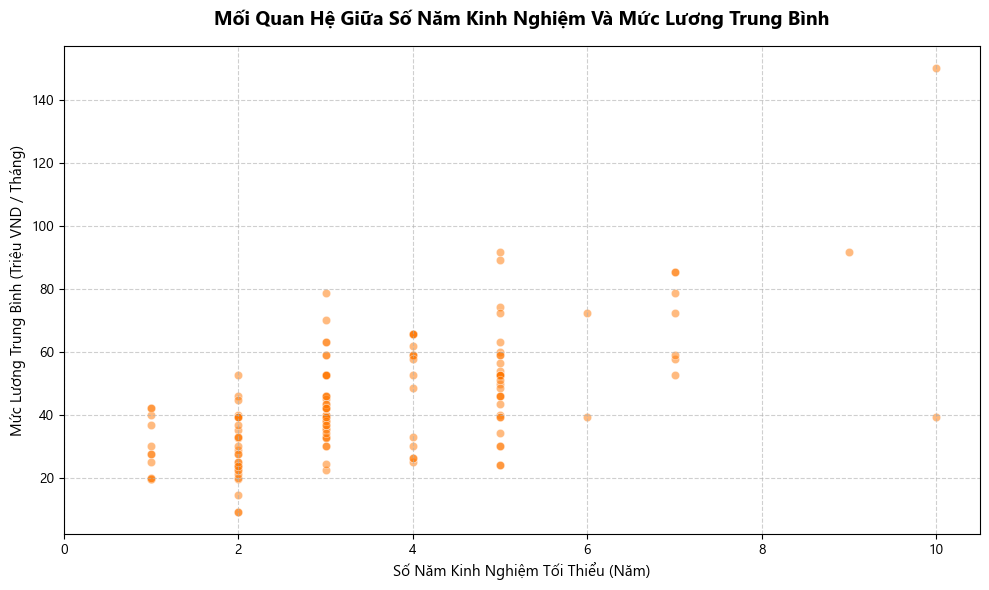

In [111]:
# 1. Cấu hình để vẽ biểu đồ hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI' # Hoặc 'Arial', 'Tahoma' tùy máy em
plt.figure(figsize=(10, 6))

# 2. Loại bỏ các dòng bị Null ở cả 2 cột để tránh lỗi đồ thị
df_plot = df.dropna(subset=['mean_salary', 'experience_min_year'])

# Mẹo quy đổi mức lương sang đơn vị "Triệu VND" cho trục tọa độ ngắn gọn, dễ nhìn
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


# 3. Vẽ b
sns.scatterplot(
    data=df_plot, 
    x='experience_min_year', 
    y='mean_salary_million', 
    alpha=0.5, # Độ trong suốt để nhìn rõ những chỗ các chấm đè lên nhau
    color="#ff7700"
)


# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học
plt.title('Mối Quan Hệ Giữa Số Năm Kinh Nghiệm Và Mức Lương Trung Bình', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số Năm Kinh Nghiệm Tối Thiểu (Năm)', fontsize=11)
plt.ylabel('Mức Lương Trung Bình (Triệu VND / Tháng)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6) # Thêm lưới mờ cho dễ dóng hàng

# Thới hạn hiển thị trục X gọn gàng từ 0 đến tối đa số năm kinh nghiệm thực tế trong data
plt.xlim(0, df_plot['experience_min_year'].max() + 0.5)

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_1236\1035102999.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


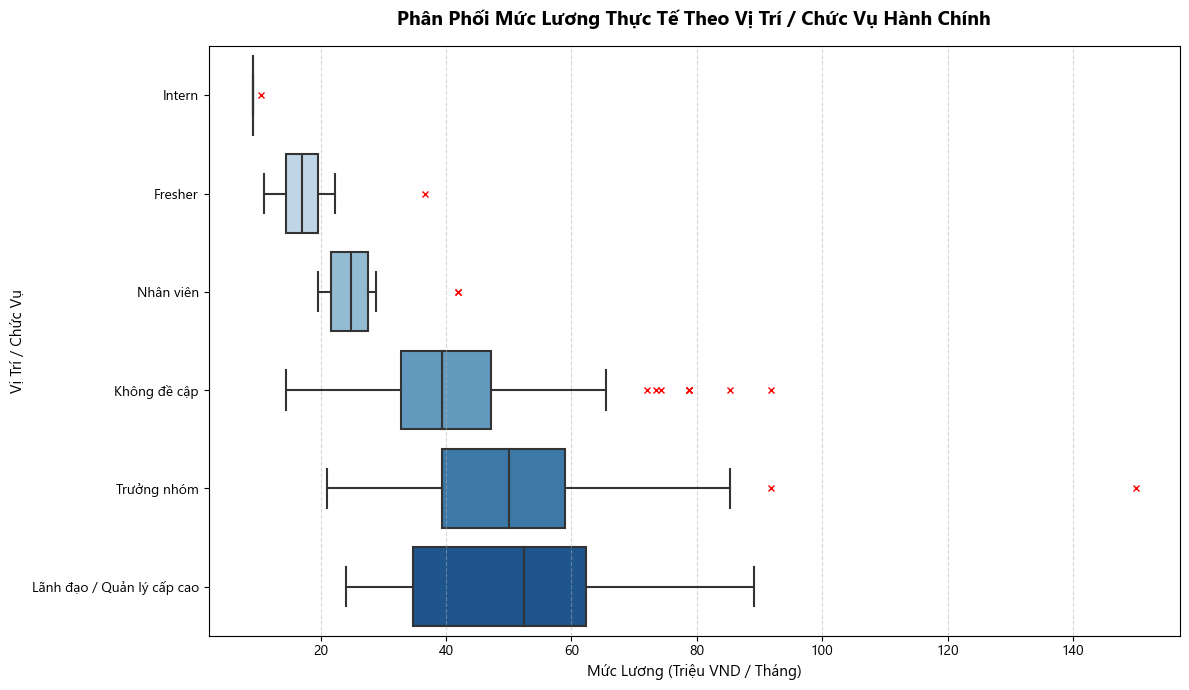

In [ ]:
# LƯƠNG VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


In [109]:
df[['index', 'salary','mean_salary', 'experience_min_year']]

,index,salary,mean_salary,experience_min_year
0,1,20-25tr gross,2.250000e+07,3.0
1,2,You'll love it,NaN,1.0
2,3,Up to 2800 usd,7.344400e+07,NaN
3,4,"Up-to 34,000 usd/year",7.431833e+07,5.0
4,5,You'll love it,NaN,2.0
...,...,...,...,...
1143,1144,Very attractive!!!,NaN,NaN
1144,1145,Very attractive!!!,NaN,NaN
1145,1146,Very attractive!!!,NaN,5.0
1146,1147,You'll love it,NaN,5.0


In [62]:
# ĐỔI CHỖ CỘT KINH NGHIỆM CHO DỄ CHECK OUTLIER


# 1. Lấy ra toàn bộ danh sách tên cột hiện tại, loại trừ cột kinh nghiệm ra
cols = [c for c in df.columns if c != 'experience_min_year']

# 2. Thêm cột kinh nghiệm vào cuối cùng của danh sách đó
cols.append('experience_min_year')

# 3. Áp dụng lại thứ tự mới này cho DataFrame
df = df[cols]


In [ ]:
# saved
df.to_csv("data_ITviec_5.csv", index=False, encoding="utf-8-sig")

df

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_posted,job_skills,...,co_hien_thi_luong,loai_tien_te,viet_tat_trieu,tinh_theo_nam,salary_min,salary_max,mean_salary_no_unit,mean_salary,experience_min_year,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,20-25tr gross,vnd,triệu,None,20.0,25.0,22.5,2.250000e+07,3.0,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,None,None,None,None,NaN,NaN,NaN,NaN,1.0,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,up to 2800 usd,usd,None,None,2800.0,2800.0,2800.0,7.344400e+07,NaN,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,"Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,up-to 34000 usd/year,usd,None,năm,34000.0,34000.0,34000.0,7.431833e+07,5.0,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,None,None,None,None,NaN,NaN,NaN,NaN,2.0,Không đề cập
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,Very attractive!!!,At office,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",...,None,None,None,None,NaN,NaN,NaN,NaN,NaN,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,Very attractive!!!,At office,2026-06-12,"iOS, API, Database, OOP, Swift, English",...,None,None,None,None,NaN,NaN,NaN,NaN,NaN,Fresher
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,Very attractive!!!,At office,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",...,None,None,None,None,NaN,NaN,NaN,NaN,5.0,Trưởng nhóm
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,Database Administrator,[Senior/ Lead] Fullstack Engineer,Crossian,Hà Nội,You'll love it,At office,2026-06-12,"Fullstack, Database, Python, NodeJS, JavaScrip...",...,None,None,None,None,NaN,NaN,NaN,NaN,5.0,Trưởng nhóm


In [102]:
# Tìm dòng có cột 'index' bằng 80 và sửa giá trị cột kinh nghiệm thành 5
df.loc[df['index'] == 81, 'experience_min_year'] = 5
df.loc[df['index'] == 4, 'experience_min_year'] = 5
df.loc[df['index'] == 403, 'experience_min_year'] = 3
df.loc[df['index'] == 38, 'experience_min_year'] = 1
df.loc[df['index'] == 1108, 'experience_min_year'] = 1


df.loc[df['index'] == 700, 'job_level'] = "Senior"
df.loc[df['index'] == 700, 'job_position'] = "Trưởng nhóm"


df[['index', 'salary','mean_salary', 'experience_min_year']]

,index,salary,mean_salary,experience_min_year
0,1,20-25tr gross,2.250000e+07,3.0
1,2,You'll love it,NaN,1.0
2,3,Up to 2800 usd,7.344400e+07,NaN
3,4,"Up-to 34,000 usd/year",7.431833e+07,5.0
4,5,You'll love it,NaN,2.0
...,...,...,...,...
1143,1144,Very attractive!!!,NaN,NaN
1144,1145,Very attractive!!!,NaN,NaN
1145,1146,Very attractive!!!,NaN,5.0
1146,1147,You'll love it,NaN,5.0


In [ ]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['test', 'co_hien_thi_luong', 'loai_tien_te', 'viet_tat_trieu', 'tinh_theo_nam', 
                      'salary_min', 'salary_max', 'mean_salary_no_unit'])

In [ ]:
# saved
df.to_csv("data_ITviec_6.csv", index=False, encoding="utf-8-sig")

df

## 3.3. Hình thức làm việc

In [5]:
# review file data
filename_6 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_6.csv"
df = pd.read_csv(filename_6)

df

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_posted,job_skills,...,benefits,source,text_combined,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position_test,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,20-25tr gross,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",...,Attractive salary and bonus with annual revisi...,2,"Main Mission Within the Data & AI Hub, you wil...",Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,You'll love it,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Up to 2800 usd,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",...,"A worklife balance: Hybrid working model, 15 d...",2,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,"Up-to 34,000 usd/year",At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",...,"At Crossian, our people are the key to our suc...",2,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,You'll love it,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",...,"Compensation: Competitive, tied to impact Revi...",2,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,2026-05-01,Undefined,NaN,2.0,Không đề cập,Không đề cập
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,Very attractive!!!,At office,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",...,● Competitive salary with annual performance r...,2,We are looking for a Junior Android Developer ...,Đại học,2026-07-12,Fresher,NaN,NaN,Nhân viên,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,Very attractive!!!,At office,2026-06-12,"iOS, API, Database, OOP, Swift, English",...,● Competitive salary with annual performance r...,2,1. Education ● Bachelor’s degree in Computer S...,Đại học,2026-07-12,Fresher,NaN,NaN,Nhân viên,Fresher
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,Very attractive!!!,At office,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",...,Lương thỏa thuận Thưởng tháng 13 và thưởng hiệ...,2,Chúng tôi đang tìm kiếm Senior Backend Enginee...,Not Mentioned,2026-07-12,Senior,NaN,5.0,Trưởng nhóm,Trưởng nhóm
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,Database Administrator,[Senior/ Lead] Fullstack Engineer,Crossian,Hà Nội,You'll love it,At office,2026-06-12,"Fullstack, Database, Python, NodeJS, JavaScrip...",...,Ownership: Direct ownership of real work strea...,2,Crossian is a highgrowth technologydriven ecom...,Not Mentioned,2026-07-12,Senior,NaN,5.0,Trưởng nhóm,Trưởng nhóm


In [6]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['salary', 'job_position_test', 'job_level'])

df.head(5)

,index,job_url,search_keyword,job_title,company_name,location,job_type,date_posted,job_skills,job_expertise,...,description,requirements,benefits,source,text_combined,edu,date_deadline,mean_salary,experience_min_year,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,...,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,"Main Mission Within the Data & AI Hub, you wil...",Đại học,2026-05-05,2.250000e+07,3.0,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,...,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,2026-05-04,NaN,1.0,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,...,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,2026-05-02,7.344400e+07,NaN,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,...,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,2026-05-02,7.431833e+07,5.0,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,...,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,2026-05-01,NaN,2.0,Không đề cập


In [13]:
def assign_work_type(work_type_text):
    # Chuẩn hóa chữ về dạng thường, không dấu
    t = clean_vietnamese_text(str(work_type_text))
    
    if not t or t == 'nan':
        return "Khác"
    
    # 1. Toàn thời gian
    full_time_keywords = ['toan thoi gian', 'at office', 'lam viec tai van phong', 'full time', 'full-time', 'fulltime']
    if any(k in t for k in full_time_keywords):
        return "Fulltime"
        
    # 2. Bán thời gian
    part_time_keywords = ['ban thoi gian', 'part time', 'part-time', 'parttime', 'thoi vu', 'hop dong thoi vu']
    if any(k in t for k in part_time_keywords):
        return "Parttime"
        

    # 4. Hybrid
    hybrid_keywords = ['hybrid']
    if any(k in t for k in hybrid_keywords):
        return "Hybrid"
    

    # 3. Remote
    remote_keywords = ['remote', 'lam tai nha', 'online', 'lam tu xa', 'work from home', 'wfh']
    if any(k in t for k in remote_keywords):
        return "Remote"
        

    # 5. Khác (Các từ khóa còn lại hoặc không khớp nhóm nào)
    # Bao gồm các từ: thoi vu, nghe tu do, hop dong thoi vu
    return "Khác"

In [14]:
# Tạo cột mới 'work_type_clean' dựa trên cột 'work_type' hiện tại
df['work_type_clean'] = df['job_type'].apply(assign_work_type)

# In thử kết quả để kiểm tra
df[['job_type', 'work_type_clean']]

,job_type,work_type_clean
0,At office,Fulltime
1,At office,Fulltime
2,Hybrid,Hybrid
3,At office,Fulltime
4,At office,Fulltime
...,...,...
1143,At office,Fulltime
1144,At office,Fulltime
1145,At office,Fulltime
1146,At office,Fulltime


In [16]:
# Đếm tần suất từng loại hình công việc sau khi đã làm sạch
df['work_type_clean'].value_counts()

work_type_clean
Fulltime    961
Hybrid      161
Remote       26
Name: count, dtype: int64

In [17]:
df['job_type'] = df['work_type_clean']

In [18]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['work_type_clean'])

In [19]:
# saved
df.to_csv("data_ITviec_7.csv", index=False, encoding="utf-8-sig")

df

,index,job_url,search_keyword,job_title,company_name,location,job_type,date_posted,job_skills,job_expertise,...,description,requirements,benefits,source,text_combined,edu,date_deadline,mean_salary,experience_min_year,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,Fulltime,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,...,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,"Main Mission Within the Data & AI Hub, you wil...",Đại học,2026-05-05,2.250000e+07,3.0,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,Fulltime,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,...,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,2026-05-04,NaN,1.0,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,...,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,2026-05-02,7.344400e+07,NaN,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,Fulltime,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,...,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,2026-05-02,7.431833e+07,5.0,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,Fulltime,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,...,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,2026-05-01,NaN,2.0,Không đề cập
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,Fulltime,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",Mobile Application Developer,...,We are looking for a Junior Android Developer ...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,We are looking for a Junior Android Developer ...,Đại học,2026-07-12,NaN,NaN,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,Fulltime,2026-06-12,"iOS, API, Database, OOP, Swift, English",Mobile Application Developer,...,1. Education ● Bachelor’s degree in Computer S...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,1. Education ● Bachelor’s degree in Computer S...,Đại học,2026-07-12,NaN,NaN,Fresher
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,Fulltime,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",Backend Developer,...,Chúng tôi đang tìm kiếm Senior Backend Enginee...,Must Have T

In [ ]:
# review file data
filename_7 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_6.csv"
df = pd.read_csv(filename_7)

In [9]:
filtered_df = df[
    (df['experience_min_year'] > 0) & 
    (df['job_position'].isin(["Intern", "Fresher"]))
]
filtered_df[['index', 'job_url', 'job_title', 'experience_min_year', 'job_position']]


,index,job_url,job_title,experience_min_year,job_position
17,18,https://itviec.com/it-jobs/chuyen-vien-phat-tr...,Chuyên viên Phát triển MIS (Data Analyst/ Engi...,1.0,Fresher
36,37,https://itviec.com/it-jobs/business-analyst-ta...,Business Analyst - Tastify - 2-month contract,2.0,Fresher
161,162,https://itviec.com/it-jobs/software-support-he...,Software Support/Helpdesk,1.0,Fresher
202,203,https://itviec.com/it-jobs/quan-tri-he-thong-c...,Quản trị hệ thống Cơ sở Dữ liệu (DBA - Databas...,3.0,Fresher
236,237,https://itviec.com/it-jobs/ai-engineer-stt-asr...,"AI Engineer (STT / ASR, Speech / Audio ML, Pyt...",2.0,Fresher
283,284,https://itviec.com/it-jobs/teencare-ai-fullsta...,[TeenCare] AI Fullstack Engineer for EdTech Pr...,1.0,Fresher
382,383,https://itviec.com/it-jobs/system-engineer-lin...,Trưởng phòng IT,5.0,Fresher
456,457,https://itviec.com/it-jobs/devops-engineer-clo...,"DevOps Engineer( Cloud, K8S, DevSecOps)",1.0,Fresher
481,482,https://itviec.com/it-jobs/ai-agent-engineer-m...,"AI Agent Engineer (ML, Python, TypeSript, .NET...",1.0,Fresher
594,595,https://itviec.com/it-jobs/quan-tri-he-thong-c...,Quản trị hệ thống Cơ sở Dữ liệu (DBA - Databas...,3.0,Fresher


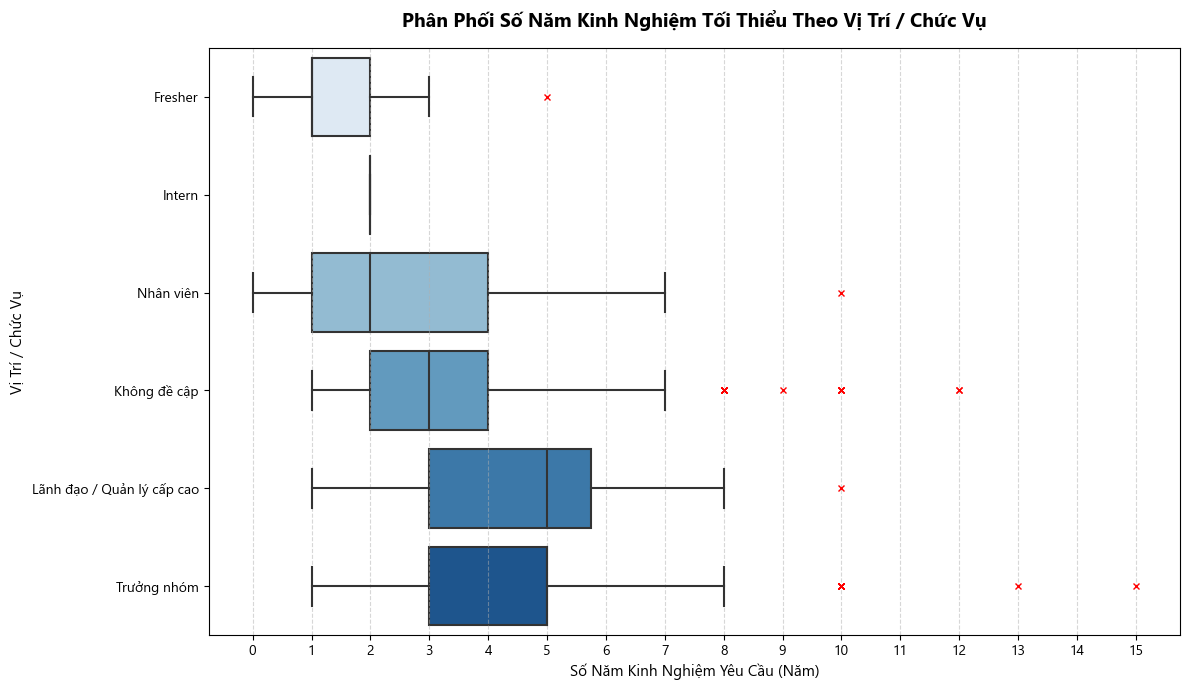

In [11]:

# KINH NGHIỆM VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
# Dùng .copy() để tránh cảnh báo SettingWithCopyWarning của Pandas
df_plot_exp = df.dropna(subset=['experience_min_year', 'job_position']).copy()

# Tự động tính trung vị (Median) năm kinh nghiệm để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions_exp = df_plot_exp.groupby('job_position')['experience_min_year'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm rõ các giá trị đột biến (Outliers)
sns.boxplot(
    data=df_plot_exp,
    x='experience_min_year',
    y='job_position',
    order=order_positions_exp,
    palette='Blues',  # Đổi sang tone màu Xanh 
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Số Năm Kinh Nghiệm Tối Thiểu Theo Vị Trí / Chức Vụ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số Năm Kinh Nghiệm Yêu Cầu (Năm)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng số năm

# Thiết lập các mốc trục x (tick) là số nguyên (0, 1, 2, 3...) vì số năm kinh nghiệm thường là số chẵn
plt.xticks(range(int(df_plot_exp['experience_min_year'].min()), int(df_plot_exp['experience_min_year'].max()) + 1))

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


In [44]:
df.loc[df['index'] == 383, 'job_position'] = "Trưởng phòng"

df.loc[df['index'] == 383]

,index,job_url,search_keyword,job_title,company_name,location,date_posted,job_skills,job_expertise,job_domain,...,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position_test,job_position,work_type
382,383,https://itviec.com/it-jobs/system-engineer-lin...,Database Administrator,Trưởng phòng IT,CÔNG TY CỔ PHẦN MINH HƯNG M&C,Hồ Chí Minh,2026-03-15,"System Admin, Python, Database, VMware, Linux,...",Systems Engineer / Administrator,"Real Estate, Property and Construction",...,Mức lương: Thỏa thuận theo năng lực Được hưởng...,2,Đại học,2026-04-15,Fresher,NaN,5.0,Trưởng phòng,Trưởng phòng,Fulltime


In [43]:
df.loc[df['index'] == 206, 'job_position'] = "Trưởng phòng"
df.loc[df['index'] == 206]

,index,job_url,search_keyword,job_title,company_name,location,date_posted,job_skills,job_expertise,job_domain,...,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position_test,job_position,work_type
205,206,https://itviec.com/it-jobs/it-operations-suppo...,Cloud Data,IT Operations & Support Lead (1y Contractor),Bosch Global Software Technologies Company Lim...,Hồ Chí Minh,2026-03-11,"Software Architecture, Stakeholder management,...",Solution Architect,"Software Development Outsourcing, Software Pro...",...,Why BOSCH ? Because we do not just follow tren...,2,Đại học,2026-04-11,Junior/Middle,NaN,10.0,Nhân viên,Trưởng phòng,Fulltime


In [17]:
# Tạo bộ lọc (mask) cho 2 điều kiện
mask = (df['job_position'].isin(["Intern", "Fresher"])) & (df['experience_min_year'].isna())

# Dùng .loc để gán giá trị 0 cho cột 'experience_min_year' tại những dòng thỏa mãn điều kiện
df.loc[mask, 'experience_min_year'] = 0


In [18]:
df.loc[df['job_position'].isin(["Intern", "Fresher"])]

,index,job_url,search_keyword,job_title,company_name,location,salary,job_type,date_posted,job_skills,...,benefits,source,text_combined,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position_test,job_position
11,12,https://itviec.com/it-jobs/data-analyst-p-l-an...,Data Analyst,Data Analyst (P&L Analytics),FE CREDIT,Hồ Chí Minh,500 - 900 USD,At office,2026-04-03,"SQL, English",...,See yourselves in a new light In essence of jo...,2,"Coordinate with crossfunctional team to, build...",Đại học,2026-05-03,Fresher,18361000.0,0.0,Không đề cập,Fresher
17,18,https://itviec.com/it-jobs/chuyen-vien-phat-tr...,Data Analyst,Chuyên viên Phát triển MIS (Data Analyst/ Engi...,SACOMBANK,Hồ Chí Minh,You'll love it,At office,2026-03-12,"Data Analysis, PL/SQL, Oracle, Data modeling, ...",...,CHẾ ĐỘ ĐÃI NGỘ: Chế độ Lương và thu nhập hấp d...,2,TRÁCH NHIỆM CHÍNH Xây dựng giải pháp và lập tr...,Đại học,2026-04-12,Fresher,NaN,1.0,Nhân viên,Fresher
36,37,https://itviec.com/it-jobs/business-analyst-ta...,Business Intelligence,Business Analyst - Tastify - 2-month contract,SUCAFINA,Hồ Chí Minh,"500 - 1,000 USD",At office,2026-04-03,"Business Analysis, Jira, Data Quality Tools, C...",...,Competitive salary package WFH Benefit once a ...,2,The responsibilities are included but not limi...,Đại học,2026-05-03,Fresher,19672500.0,2.0,Không đề cập,Fresher
143,144,https://itviec.com/it-jobs/cloud-consultant-ne...,Cloud Data,Cloud Consultant,NetNam Corporation - Branch in HCMC,Hồ Chí Minh,NaN,At office,2026-03-06,"Cloud, GCP, VMware, Azure, AWS, CloudFormation",...,"1. Thu nhập & Thưởng Lương cạnh tranh, thỏa th...",2,Tư vấn Phối hợp với Sales làm rõ yêu cầu kỹ th...,Not Mentioned,2026-04-06,Fresher,NaN,0.0,Không đề cập,Fresher
161,162,https://itviec.com/it-jobs/software-support-he...,Cloud Data,Software Support/Helpdesk,NaviWorld,Hà Nội,NaN,At office,2026-04-02,"Business Analysis, Windows, Microsoft Dynamics...",...,Why Join Us Work with enterprise ERP systems u...,2,NaviWorld Vietnam is looking for a motivated L...,Đại học,2026-05-02,Fresher,NaN,1.0,Nhân viên,Fresher
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1084,1085,https://itviec.com/it-jobs/thuc-tap-sinh-khoa-...,Data Visualization,Thực tập sinh Khoa học Dữ liệu,VCS Viet Nam,Hà Nội,300 - 500 USD,At office,2026-06-08,"Python, SQL",...,a) Thu nhập: Mức lương hấp dẫn (thỏa thuận the...,2,a) Tạo lập và Xử lý dữ liệu: Thiết kế và tối ư...,Đại học,2026-07-08,Intern,10492000.0,0.0,Intern,Intern
1132,1133,https://itviec.com/it-jobs/ai-engineer-chailea...,Machine Learning,AI Engineer,Chailease,Hồ Chí Minh,You'll love it,At office,2026-06-10,"Python, SQL, API, TypeScript, NodeJS",...,Thời gian làm việc: 5 ngày/tuần (Thứ 2 – Thứ 6...,2,Tích hợp AI & Phát triển Tính năng: Lập trình ...,Not Mentioned,2026-07-10,Fresher,NaN,1.0,Không đề cập,Fresher
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,Very attractive!!!,At office,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",...,● Competitive salary with annual performance r...,2,We are looking for a Junior Android Developer ...,Đại học,2026-07-12,Fresher,NaN,0.0,Nhân viên,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,Very attractive!!!,At office,2026-06-12,"iOS, API, Database, OOP, Swift, English",...,● Competitive salary with annual performance r...,2,1. Education ● Bachelor’s degree in Computer S...,Đại học,2026-07-12,Fresher,NaN,0.0,Nhân viên,Fresher


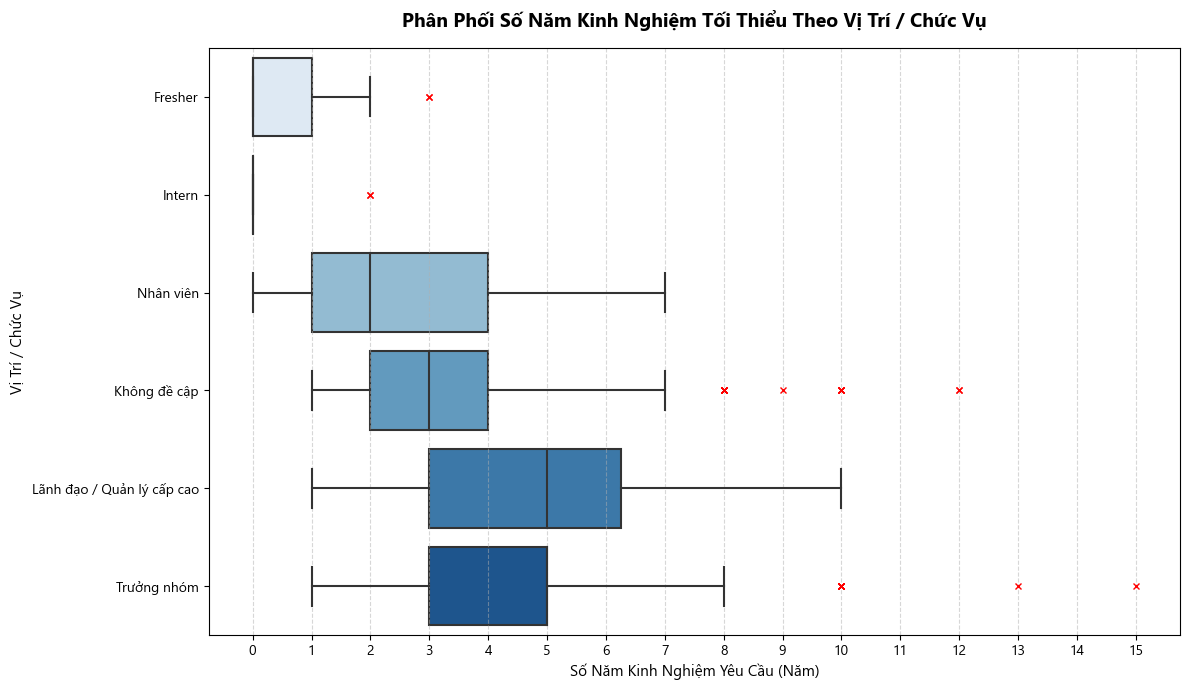

In [19]:

# KINH NGHIỆM VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
# Dùng .copy() để tránh cảnh báo SettingWithCopyWarning của Pandas
df_plot_exp = df.dropna(subset=['experience_min_year', 'job_position']).copy()

# Tự động tính trung vị (Median) năm kinh nghiệm để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions_exp = df_plot_exp.groupby('job_position')['experience_min_year'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm rõ các giá trị đột biến (Outliers)
sns.boxplot(
    data=df_plot_exp,
    x='experience_min_year',
    y='job_position',
    order=order_positions_exp,
    palette='Blues',  # Đổi sang tone màu Xanh 
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Số Năm Kinh Nghiệm Tối Thiểu Theo Vị Trí / Chức Vụ', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số Năm Kinh Nghiệm Yêu Cầu (Năm)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng số năm

# Thiết lập các mốc trục x (tick) là số nguyên (0, 1, 2, 3...) vì số năm kinh nghiệm thường là số chẵn
plt.xticks(range(int(df_plot_exp['experience_min_year'].min()), int(df_plot_exp['experience_min_year'].max()) + 1))

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


In [24]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['text_combined', 'salary'])

In [25]:
# saved
df.to_csv("data_ITviec_8.csv", index=False, encoding="utf-8-sig")


## 3.4. Xử lý lỗi vặt

In [28]:
# review file data
filename_8 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_8.csv"
df = pd.read_csv(filename_8)

In [41]:
# review file data
filename_7 = r"E:\Chuyển từ download sang\A Học tập Bách Khoa\ĐA2\Đồ án 2 _ 2025\Project_full\ETL\ETL_ITviec\data_ITviec_7.csv"
df_7 = pd.read_csv(filename_7)
df_7

,index,job_url,search_keyword,job_title,company_name,location,job_type,date_posted,job_skills,job_expertise,...,description,requirements,benefits,source,text_combined,edu,date_deadline,mean_salary,experience_min_year,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,Fulltime,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,...,"Main Mission Within the Data & AI Hub, you wil...",Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,"Main Mission Within the Data & AI Hub, you wil...",Đại học,2026-05-05,2.250000e+07,3.0,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,Fulltime,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,...,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,HO26.37 Chuyên viên Phân tích Khách hàng Doanh...,Đại học,2026-05-04,NaN,1.0,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,...,"At Goelett by S4BT, we are a dynamic team pass...",Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,"At Goelett by S4BT, we are a dynamic team pass...",Đại học,2026-05-02,7.344400e+07,NaN,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,Fulltime,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,...,ABOUT THE ROLE Crossian is a highgrowth techno...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,ABOUT THE ROLE Crossian is a highgrowth techno...,Đại học,2026-05-02,7.431833e+07,5.0,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,Fulltime,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,...,"About TeenCare AI At TeenCare AI , we work at ...","2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,"About TeenCare AI At TeenCare AI , we work at ...",Not Mentioned,2026-05-01,NaN,2.0,Không đề cập
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,Fulltime,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",Mobile Application Developer,...,We are looking for a Junior Android Developer ...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,We are looking for a Junior Android Developer ...,Đại học,2026-07-12,NaN,NaN,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,Fulltime,2026-06-12,"iOS, API, Database, OOP, Swift, English",Mobile Application Developer,...,1. Education ● Bachelor’s degree in Computer S...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,1. Education ● Bachelor’s degree in Computer S...,Đại học,2026-07-12,NaN,NaN,Fresher
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,Fulltime,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",Backend Developer,...,Chúng tôi đang tìm kiếm Senior Backend Enginee...,Must Have T

In [30]:
df

,index,job_url,search_keyword,job_title,company_name,location,job_type,date_posted,job_skills,job_expertise,...,requirements,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position_test,job_position
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,At office,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,...,Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Không đề cập
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,At office,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Không đề cập
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,Hybrid,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,...,Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Không đề cập
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,At office,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Không đề cập
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,At office,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,...,"2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,Not Mentioned,2026-05-01,Undefined,NaN,2.0,Không đề cập,Không đề cập
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1143,1144,https://itviec.com/it-jobs/junior-android-deve...,Database Administrator,Junior Android Developer (Kotlin/Java),Motorist Pte Ltd,Hồ Chí Minh,At office,2026-06-12,"Android, Java, Database, OOP, Kotlin, English",Mobile Application Developer,...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,Đại học,2026-07-12,Fresher,NaN,0.0,Nhân viên,Fresher
1144,1145,https://itviec.com/it-jobs/junior-ios-mobile-d...,Database Administrator,"Junior iOS Mobile Developer (Swift, English)",Motorist Pte Ltd,Hồ Chí Minh,At office,2026-06-12,"iOS, API, Database, OOP, Swift, English",Mobile Application Developer,...,Technical Experiences Must Have ● Bachelor’s d...,● Competitive salary with annual performance r...,2,Đại học,2026-07-12,Fresher,NaN,0.0,Nhân viên,Fresher
1145,1146,https://itviec.com/it-jobs/senior-backend-deve...,Database Administrator,"Senior Backend Developer (Java Spring Boot, BPM)",Bolt Tech,Hà Nội,At office,2026-06-12,"Java, Solution Architecture, Database, SQL, Sp...",Backend Developer,...,Must Have Từ 5 năm kinh nghiệm phát triển Back...,Lương thỏa thuận Thưởng tháng 13 và thưởng hiệ...,2,Not Mentioned,2026-07-12,Senior,NaN,5.0,Trưởng nhóm,Trưởng nhóm
1146,1147,https://itviec.com/it-jobs/senior-lead-fullsta...,Database Administrator,[Senior/ Lead] Fullstack Engineer,Crossian,Hà Nội,At office,2026-06-12,"Fullstack, Database, Python, NodeJS, JavaScrip...",Fullstack Developer,...,Education & Experience Education: Strong acade...,Ownership: Direct ownership of real work strea...,2,Not Mentioned,2026-07-12,Senior,NaN,5.0,Trưởng nhóm,Trưởng nhóm


In [42]:
df['work_type'] = df_7['job_type']

df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,date_posted,job_skills,job_expertise,job_domain,...,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position_test,job_position,work_type
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Không đề cập,Fulltime
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,"Banking, Financial Services",...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Không đề cập,Fulltime
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Không đề cập,Hybrid
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,"E-commerce, Software Products and Web Services",...,"At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Không đề cập,Fulltime
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,...,"Compensation: Competitive, tied to impact Revi...",2,Not Mentioned,2026-05-01,Undefined,NaN,2.0,Không đề cập,Không đề cập,Fulltime
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,Hồ Chí Minh,2026-03-31,"Python, SQL",Data Analyst,"E-commerce, IT Services and IT Consulting, Sof...",...,Modern working equipment provided Competitive ...,2,Đại học,2026-04-30,Senior,7.082100e+07,NaN,Trưởng nhóm,Trưởng nhóm,Fulltime
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,Hà Nội,2026-03-30,"Python, SQL",Data Analyst,"Banking, Financial Services",...,THE BENEFITS AND PERKS 1. Generous compensatio...,2,Not Mentioned,2026-04-30,Senior,5.901750e+07,4.0,Trưởng nhóm,Trưởng nhóm,Hybrid
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,Hà Nội,2026-03-25,"Data Analysis, Power BI, Microsoft SQL Server,...",Data Analyst,"Banking, Financial Services",...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-04-25,Undefined,NaN,2.0,Không đề cập,Không đề cập,Fulltime
8,9,https://itviec.com/it-jobs/data-analyst-sql-py...,Data Analyst,"Data Analyst (SQL, Python, Data Analysis)","Sports Marketing Software Services CO.,LTD",Hồ Chí Minh,2026-03-25,"Data Analysis, Business Intelligence, JSON, AP...",Data Analyst,Sports and Fitness,...,Salary 21.200.000 26.500.000 VND Bonus: detail...,2,Đại học,2026-04-25,Undefined,2.360700e+07,2.0,Không đề cập,Không đề cập,Fulltime
9,10,https://itviec.com/it-jobs/telecom-business-ar...,Data Analyst,Telecom Business Architect,Huawei,Hà Nội,2026-04-01,"Business Analysis, Data Analysis",Data Analyst,Telecommunication,...,Working time: Monday to Friday (08:0018:00). C...,2,Đại học,2026-05-01,Undefined,5.246000e+07,7.0,Không đề cập,Không đề cập,Fulltime


In [3]:
# Thay "Fulltime" bằng "Full-time"
df.loc[df['work_type'] == "Fulltime", 'work_type'] = 'Full-time'

df['work_type'].value_counts()

work_type
Full-time    961
Hybrid       161
Remote        26
Name: count, dtype: int64

In [49]:
df.head(10)

,index,job_url,search_keyword,job_title,company_name,location,date_posted,job_skills,job_expertise,job_domain,...,requirements,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position,work_type
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,...,Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Fulltime
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,"Banking, Financial Services",...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Fulltime
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,...,Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Hybrid
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,"E-commerce, Software Products and Web Services",...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Fulltime
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,...,"2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,Not Mentioned,2026-05-01,Undefined,NaN,2.0,Không đề cập,Fulltime
5,6,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst/Scientist,KOSATEC EMPOWERING GLOBAL INNOVATION,Hồ Chí Minh,2026-03-31,"Python, SQL",Data Analyst,"E-commerce, IT Services and IT Consulting, Sof...",...,Bachelor in Information Technology or related ...,Modern working equipment provided Competitive ...,2,Đại học,2026-04-30,Senior,7.082100e+07,NaN,Trưởng nhóm,Fulltime
6,7,https://itviec.com/it-jobs/senior-data-analyst...,Data Analyst,Senior Data Analyst,NAB Innovation Centre Vietnam,Hà Nội,2026-03-30,"Python, SQL",Data Analyst,"Banking, Financial Services",...,YOUR SKILLS & EXPERIENCE Essential Capabilitie...,THE BENEFITS AND PERKS 1. Generous compensatio...,2,Not Mentioned,2026-04-30,Senior,5.901750e+07,4.0,Trưởng nhóm,Hybrid
7,8,https://itviec.com/it-jobs/data-analyst-data-d...,Data Analyst,Data Analyst - Data Division,MB Bank,Hà Nội,2026-03-25,"Data Analysis, Power BI, Microsoft SQL Server,...",Data Analyst,"Banking, Financial Services",...,1. Trình độ học vấn Tốt nghiệp Đại học (bằng k...,Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-04-25,Undefined,NaN,2.0,Không đề cập,Fulltime
8,9,https://itviec.com/it-jobs/data-analyst-sql-py...,Data Analyst,"Data Analyst (SQL, Python, Data Analysis)","Sports Marketing Software Services CO.,LTD",Hồ Chí Minh,2026-03-25,"Data Analysis, Business Intelligence, JSON, AP...",Data Analyst,Sports and Fitness,...,Required Skills Bachelor’s degree in Data Scie...,Salary 21.200.000 26.500.000 VND Bonus: detail...,2,Đại học,2026-04-25,Undefined,2.360700e+07,2.0,Không đề cập,Fulltime
9,10,https://itviec.com/it-jobs/telecom-business-ar...,Data Analyst,Telecom Business Archit

In [48]:
# Xóa cột phụ nếu không cần thiết nữa
df = df.drop(columns=['job_position_test'])

In [2]:
# review file data
filename_9 = r"data_ITviec_9.csv"
df = pd.read_csv(filename_9)

df.head(5)

,index,job_url,search_keyword,job_title,company_name,location,date_posted,job_skills,job_expertise,job_domain,...,requirements,benefits,source,edu,date_deadline,job_level,mean_salary,experience_min_year,job_position,work_type
0,1,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,Data Analyst/ Power BI Developer,CÔNG TY TNHH SOCOTEC VIỆT NAM,Hà Nội,2026-04-05,"Data Analysis, Databricks, SQL, Data modeling,...",Data Analyst,Materials and Mining,...,Education Bachelor's or Master's degree (35 ye...,Attractive salary and bonus with annual revisi...,2,Đại học,2026-05-05,Undefined,2.250000e+07,3.0,Không đề cập,Full-time
1,2,https://itviec.com/it-jobs/business-customer-d...,Data Analyst,Business Customer Data Analyst - Data Division,MB Bank,Hà Nội,2026-04-04,"Data Analysis, Data Warehousing, ETL, Power BI...",Data Analyst,"Banking, Financial Services",...,"Tốt nghiệp Đại học các chuyên ngành Thống kê, ...",Trải nghiệm Thu nhập hấp dẫn với gói đãi ngộ t...,2,Đại học,2026-05-04,Undefined,NaN,1.0,Không đề cập,Full-time
2,3,https://itviec.com/it-jobs/data-analyst-power-...,Data Analyst,"Data Analyst (Power BI, MSSQL, Python)",S4BT Solutions for Business Travel.,Hồ Chí Minh,2026-04-02,"Data Analysis, Power BI, SQL, Agile, Python",Data Analyst,Software Products and Web Services,...,Core Requirements: Strong proficiency in Power...,"A worklife balance: Hybrid working model, 15 d...",2,Đại học,2026-05-02,Undefined,7.344400e+07,NaN,Không đề cập,Hybrid
3,4,https://itviec.com/it-jobs/supply-chain-data-a...,Data Analyst,"Supply Chain Data Analyst (Total up-to 34,000 ...",Crossian,Hà Nội,2026-04-02,"Data Analysis, Looker, Tableau, Power BI, English",Data Analyst,"E-commerce, Software Products and Web Services",...,"Bachelor's degree in data science, Statistics,...","At Crossian, our people are the key to our suc...",2,Đại học,2026-05-02,Undefined,7.431833e+07,5.0,Không đề cập,Full-time
4,5,https://itviec.com/it-jobs/data-analyst-sql-bi...,Data Analyst,"Data Analyst (SQL, BI tools) for Edtech project",CÔNG TY TNHH TEENUP,Hà Nội,2026-04-01,"Data Analysis, Microsoft Power Apps, SQL",Data Analyst,Education and Training,...,"2+ years in data, analytics, strategy, consult...","Compensation: Competitive, tied to impact Revi...",2,Ko yêu cầu,2026-05-01,Undefined,NaN,2.0,Không đề cập,Full-time


In [4]:
df.loc[df['edu'] == "Not Mentioned", 'edu'] = 'Ko yêu cầu'

df['edu'].value_counts()

edu
Đại học       528
Ko yêu cầu    505
Cao học        90
Cao đẳng       25
Name: count, dtype: int64

In [4]:
# saved
df.to_csv("data_ITviec_9.csv", index=False, encoding="utf-8-sig")

C:\Users\HAN NGA\AppData\Local\Temp\ipykernel_5132\1035102999.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000


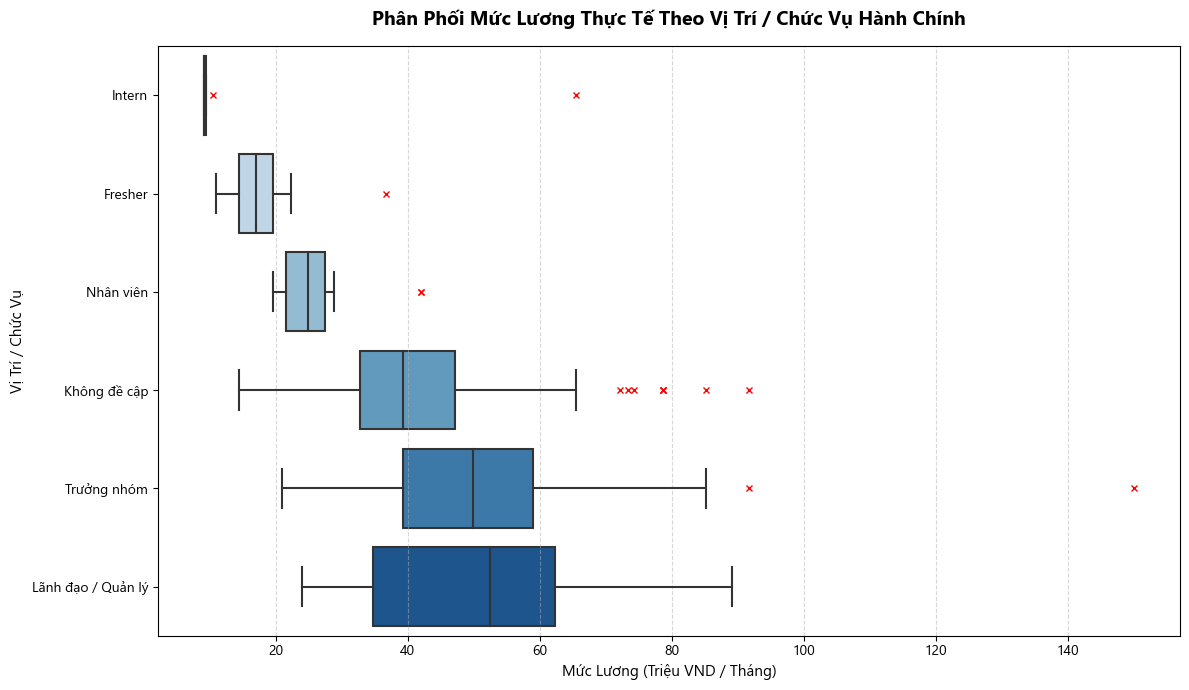

In [6]:
# LƯƠNG VÀ CHỨC VỊ

# 1. Cấu hình hiển thị đúng font tiếng Việt không bị lỗi ô vuông
plt.rcParams['font.family'] = 'Segoe UI'  # Hoặc 'Arial', 'Tahoma'
plt.figure(figsize=(12, 7))

# 2. Dọn dẹp dữ liệu trống (Null) trước khi vẽ
df_plot = df.dropna(subset=['mean_salary', 'job_position'])

# Quy đổi đơn vị lương sang "Triệu VND" cho trục tọa độ tinh tế, sạch sẽ
df_plot['mean_salary_million'] = df_plot['mean_salary'] / 1000000

# Tự động tính trung vị (Median) lương để sắp xếp thứ tự các chức vụ từ thấp đến cao
order_positions = df_plot.groupby('job_position')['mean_salary_million'].median().sort_values().index

# 3. Vẽ biểu đồ Boxplot ngang
# Thuộc tính flierprops dùng để làm đẹp các chấm lương đột biến (Outliers)
sns.boxplot(
    data=df_plot,
    x='mean_salary_million',
    y='job_position',
    order=order_positions,
    palette='Blues',  # Hệ màu xanh dương chuyển sắc theo cấp bậc nhân sự
    flierprops={"marker": "x", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5} # Outliers màu đỏ gạch chéo
)

# 4. Trang trí biểu đồ chuẩn phong cách báo cáo khoa học xuất sắc
plt.title('Phân Phối Mức Lương Thực Tế Theo Vị Trí / Chức Vụ Hành Chính', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mức Lương (Triệu VND / Tháng)', fontsize=11)
plt.ylabel('Vị Trí / Chức Vụ', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)  # Lưới dọc mờ để dễ dóng hàng tiền

# 5. Hiển thị biểu đồ
plt.tight_layout()
plt.show()


## 3.5. Lỗi job_position Intern/ Fresher

In [3]:
df['job_position'].value_counts()

job_position
Không đề cập          565
Trưởng nhóm           382
Nhân viên              75
Fresher                51
Lãnh đạo / Quản lý     43
Intern                 20
Trưởng phòng           12
Name: count, dtype: int64

In [4]:
df.loc[df['job_position'] == "Fresher", 'job_position'] = 'Thực tập / Mới tốt nghiệp'
df.loc[df['job_position'] == "Intern", 'job_position'] = 'Thực tập / Mới tốt nghiệp'

df['job_position'].value_counts()

job_position
Không đề cập                 565
Trưởng nhóm                  382
Nhân viên                     75
Thực tập / Mới tốt nghiệp     71
Lãnh đạo / Quản lý            43
Trưởng phòng                  12
Name: count, dtype: int64

In [5]:
# saved
df.to_csv("data_ITviec_9.csv", index=False, encoding="utf-8-sig")